In [ ]:
from pathlib import Path
import sys

# Localizar la raiz del repositorio desde Jupyter o terminal
RAIZ_REPO = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "notebooks").is_dir() and (p / "datos").is_dir()),
    None
)
if RAIZ_REPO is None:
    raise FileNotFoundError("Ejecuta desde el repositorio caso-itam")

sys.path.insert(0, str(RAIZ_REPO / "src"))


##  Rao-Yu, comparación de métodos, diagnósticos y benchmarking

In [ ]:
# Carga de insumos y verificación del punto de partida

# Objetivo: confirmar que partimos exactamente de donde terminó el día 10.
# Nada de lo que sigue debe cambiar esas cifras; si cambian, el error está hoy.

from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import statsmodels.api as sm

import sae_utils as su          # funciones de los días 9 y 10, sin cambios

pd.set_option("display.width", 200)

# --- Rutas (las mismas del día 10) -------------------------------------------
BASE = RAIZ_REPO
RUTA_DATOS  = BASE / "datos" / "procesados"
RUTA_FGJ    = BASE / "resultados" / "modelo_supervivencia"
RUTA_D10    = BASE / "resultados" / "estimacion_areas_pequenas"            # salidas de ayer
RUTA_SALIDA = BASE / "resultados" / "comparacion_modelos"            # salidas de hoy, aparte
RUTA_SALIDA.mkdir(exist_ok=True)

# --- Insumos ------------------------------------------------------------------
# Versiones vigentes: maestro sin sufijo (53 columnas) y directos v2 (480 filas).
# Los maestro_v0–v3 y estimaciones_directas sin sufijo son versiones viejas.
maestro   = pd.read_parquet(RUTA_DATOS / "maestro_alcaldia.parquet")
directos  = pd.read_parquet(RUTA_DATOS / "estimaciones_directas_v2.parquet")
cov_fgj   = pd.read_parquet(RUTA_FGJ / "covariables_fgj_alcaldia_anio.parquet")
eblup_d10 = pd.read_parquet(RUTA_D10 / "eblup_resultados.parquet")
resumen_d10 = pd.read_csv(RUTA_D10 / "eblup_resumen_ajustes.csv")

assert maestro.shape == (80, 53)
assert directos.shape[0] == 480
assert eblup_d10.shape == (1040, 33)
assert len(resumen_d10) == 63

# --- Base de análisis: misma construcción que la celda 4 del día 10 ----------
base, covs = su.construir_base(directos, maestro, cov_fgj)
print(f"Base de ocurrencia: {base.shape[0]} filas "
      f"({base['alc'].nunique()} alcaldías × {base['anio_ref'].nunique()} años × 3 parámetros)")

# --- Verificación 1: el módulo reproduce las σ²_u del día 10 ------------------
# Si esto falla, sae_utils.py no es fiel al cuaderno anterior y no seguimos.
print("\nσ²_u agrupado, módulo contra día 10:")
for (p, etq), cv in su.ESPECIFICACIONES.items():
    for metodo in ["reml", "ajustada"]:
        _, info = su.ajustar_fh(base[base["param"] == p], cv, True, metodo)
        ref = resumen_d10.query("param == @p and especificacion == @etq and "
                                "modelo == 'agrupado' and metodo == @metodo")["s2u"].iloc[0]
        assert abs(info["s2u"] - ref) < 1e-12, f"{p} {etq} {metodo} no coincide"
    print(f"  {p} {etq:12s} OK  (REML σ²_u = {ref if metodo=='reml' else info['s2u']:.6f})")

# --- Verificación 2: las cifras del resultado nulo, recalculadas -------------
# Estas son las que motivan el Rao-Yu. Las recalculo desde el archivo
# en lugar de copiarlas del resumen.
g = eblup_d10.query("modelo == 'agrupado' and especificacion == 'principal'").copy()
rango = lambda s: s.max() - s.min()
tabla = pd.DataFrame({
    "gamma_mediana":   g.groupby("param")["gamma"].median(),
    "rango_directo":   g.groupby(["param", "anio_ref"])["p_directo"].agg(rango)
                         .groupby("param").mean(),
    "rango_modelado":  g.groupby(["param", "anio_ref"])["p_modelo"].agg(rango)
                         .groupby("param").mean(),
})
# ¿Cuántas celdas tienen un IC que no toca la mediana de su año?
g["mediana_anio"] = g.groupby(["param", "anio_ref"])["p_modelo"].transform("median")
g["ic_fuera"] = (g["ic95_inf"] > g["mediana_anio"]) | (g["ic95_sup"] < g["mediana_anio"])
tabla["celdas_ic_fuera_de_80"] = g.groupby("param")["ic_fuera"].sum()

print("\nResultado nulo del agrupado (rango = promedio anual de máx − mín entre alcaldías):")
print(tabla.loc[["d", "k", "R"]].round(3).to_string())
print("\nCeldas con IC fuera de la mediana, por año:")
print(g.pivot_table(index="param", columns="anio_ref", values="ic_fuera",
                    aggfunc="sum").loc[["d", "k", "R"]].to_string())

Base de ocurrencia: 240 filas (16 alcaldías × 5 años × 3 parámetros)

σ²_u agrupado, módulo contra día 10:
  d principal    OK  (REML σ²_u = 0.000659)
  k principal    OK  (REML σ²_u = 0.006636)
  k sens_acceso  OK  (REML σ²_u = 0.007065)
  R principal    OK  (REML σ²_u = 0.000766)
  R sens_sesnsp  OK  (REML σ²_u = 0.000673)

Resultado nulo del agrupado (rango = promedio anual de máx − mín entre alcaldías):
       gamma_mediana  rango_directo  rango_modelado  celdas_ic_fuera_de_80
param                                                                     
d              0.110          0.175           0.053                      6
k              0.195          0.541           0.113                      0
R              0.173          0.152           0.031                      0

Celdas con IC fuera de la mediana, por año:
anio_ref  2020  2021  2022  2023  2024
param                                 
d            0     1     3     2     0
k            0     0     0     0     0
R            

### Modelo intermedio: Fay-Herriot con efecto de alcaldía

In [ ]:
# EL MODELO
#   θ_at = x_at'β + u_a + e_at
#     a = alcaldía (16), t = año (5)
#     u_a  ~ N(0, σ²_u)    UN efecto por alcaldía, el MISMO en los cinco años
#     e_at ~ N(0, ψ_at)    error de muestreo, ψ conocida (var_theta_asen)
#
# Diferencia con el agrupado: allá había un u por CELDA (80 efectos,
# independientes entre sí). Aquí hay 16, uno por alcaldía. Entonces las cinco
# celdas de Iztapalapa comparten el mismo u y se informan mutuamente.
#
# LA ESTRUCTURA DE COVARIANZA
#   Cov(θ_at, θ_bs) = σ²_u + ψ_at   si a = b y t = s   (misma celda)
#                   = σ²_u          si a = b y t ≠ s   (misma alcaldía, otro año)
#                   = 0             si a ≠ b
#   En matriz: V = σ²_u · ZZ' + Ψ, con Z la matriz indicadora de alcaldía (80×16).
#   ZZ' tiene un 1 en (i, j) cuando las celdas i y j son de la misma alcaldía.
#   V ya no es diagonal: es diagonal POR BLOQUES, un bloque 5×5 por alcaldía.
#
# EL FACTOR DE ENCOGIMIENTO, GENERALIZADO
#   El predictor es  θ̂ = Xβ̂ + H(θ_dir − Xβ̂),  con H = C·V⁻¹ y C = σ²_u·ZZ'.
#   La fila de H de una celda dice cuánto pesa cada directo en su predicción.
#   Definimos  peso_area = suma de esa fila sobre las celdas de su MISMA alcaldía.
#     - En el Fay-Herriot agrupado, peso_area = γ (solo pesa su propia celda).
#     - Aquí, peso_area = σ²_u·S_a / (1 + σ²_u·S_a), con S_a = Σ_t 1/ψ_at.
#       Es un γ donde la ψ de la celda se sustituye por la de la MEDIA
#       ponderada de la alcaldía, que es ~5 veces menor. Por eso se esperaba
#       que subiera.
#   Así el encogimiento es comparable entre todos los métodos de hoy.
#
# LA ESTIMACIÓN
#   REML por scoring de Fisher, igual que el día 10, pero escrita para V general
#   con K componentes de varianza (V = Ψ + Σ_k σ²_k G_k). Hoy K = 1; el Rao-Yu
#   reusa esta misma función con K = 2.
#   ECM = g1 + g2 + 2·g3 (Prasad-Rao generalizado, Das-Jiang-Rao 2004).
#   g3 se calcula con derivadas numéricas de H respecto a σ², para no derivar
#   a mano una fórmula distinta por cada modelo.

def reml_componentes(y, X, psi, G_lista, tol=1e-10, max_iter=500):
    """REML con V = diag(psi) + Σ_k s_k G_k. Scoring de Fisher proyectado:
    si una componente está en 0 y el score la empuja hacia abajo, se queda en 0
    (eso es la frontera). Devuelve (s, iteraciones, log-verosimilitud, información)."""
    K = len(G_lista)

    def componentes(s):
        V = np.diag(psi) + sum(sk * Gk for sk, Gk in zip(s, G_lista))
        Vi = np.linalg.inv(V)
        XtVi = X.T @ Vi
        A = np.linalg.inv(XtVi @ X)                    # (X'V⁻¹X)⁻¹
        P = Vi - XtVi.T @ A @ XtVi                     # proyector de REML
        Py = P @ y
        PG = [P @ Gk for Gk in G_lista]
        score = np.array([-0.5 * np.trace(pg) + 0.5 * Py @ Gk @ Py
                          for pg, Gk in zip(PG, G_lista)])
        info = np.array([[0.5 * np.sum(PG[k] * PG[l].T) for l in range(K)]
                         for k in range(K)])           # ½ tr(P G_k P G_l)
        ll = -0.5 * (np.linalg.slogdet(V)[1] + np.linalg.slogdet(XtVi @ X)[1] + y @ Py)
        return score, info, ll

    s = np.full(K, np.median(psi))                     # mismo arranque que eblupFH
    for it in range(1, max_iter + 1):
        score, info, _ = componentes(s)
        activas = ~((s <= 0) & (score <= 0))           # las que pueden moverse
        paso = np.zeros(K)
        if activas.any():
            ia = np.ix_(activas, activas)
            paso[activas] = np.linalg.solve(info[ia], score[activas])
        nuevo = np.maximum(s + paso, 0.0)              # nunca negativas
        if np.max(np.abs(nuevo - s)) < tol:
            s = nuevo
            break
        s = nuevo
    else:
        print("  AVISO: el scoring no convergió")
    _, info, ll = componentes(s)
    return s, it, ll, info


def blup_general(theta, psi, X, G_lista, s, obs):
    """Predictor de μ = Xβ + efectos aleatorios en TODAS las celdas
    (también las que no tienen directo), con g1 y g2 del ECM."""
    Gt = sum(sk * Gk for sk, Gk in zip(s, G_lista))   # covarianza de los efectos
    V = np.diag(psi[obs]) + Gt[np.ix_(obs, obs)]
    Vi = np.linalg.inv(V)
    Xo = X[obs]
    A = np.linalg.inv(Xo.T @ Vi @ Xo)
    beta = A @ Xo.T @ Vi @ theta[obs]                  # MCG
    C = Gt[:, obs]                                     # Cov(μ, θ_dir)
    H = C @ Vi                                         # pesos sobre los directos
    pred = X @ beta + H @ (theta[obs] - Xo @ beta)
    g1 = np.diag(Gt - H @ C.T)                         # incertidumbre con σ² y β conocidas
    D = X - H @ Xo
    g2 = np.einsum("ij,jk,ik->i", D, A, D)             # por estimar β
    return pred, beta, H, g1, g2


def g3_numerico(psi, X, G_lista, s, obs, info, h=1e-7):
    """g3 = tr[(∂h_i/∂σ²) V (∂h_i/∂σ²)' · I⁻¹]: costo de estimar σ²."""
    if np.any(s <= 0):          # en la frontera g3 no está definido: se omite
        return np.zeros(X.shape[0])
    def H_de(s_):
        Gt = sum(sk * Gk for sk, Gk in zip(s_, G_lista))
        V = np.diag(psi[obs]) + Gt[np.ix_(obs, obs)]
        return Gt[:, obs] @ np.linalg.inv(V), V
    _, V0 = H_de(s)
    derivadas = []
    for k in range(len(s)):
        e = np.zeros(len(s)); e[k] = max(h, h * s[k])
        derivadas.append((H_de(s + e)[0] - H_de(s - e)[0]) / (2 * e[k]))
    Iinv = np.linalg.inv(info)
    return np.array([np.trace(np.vstack([d[i] for d in derivadas]) @ V0 @
                              np.vstack([d[i] for d in derivadas]).T @ Iinv)
                     for i in range(X.shape[0])])


def ajustar_efecto_alcaldia(df, covariables):
    df = df.sort_values(["alc", "anio_ref"]).reset_index(drop=True)
    X = su.matriz_X(df, covariables, efectos_anio=True)
    obs = df["theta"].notna().to_numpy()
    theta = df["theta"].to_numpy()
    psi = df["var_theta_asen"].to_numpy()
    Z = pd.get_dummies(df["alc"], dtype=float).to_numpy()     # 80 × 16
    G_lista = [Z @ Z.T]                                        # 80 × 80, bloques de unos

    s, it, ll, info = reml_componentes(theta[obs], X[obs], psi[obs],
                                       [G[np.ix_(obs, obs)] for G in G_lista])
    pred, beta, H, g1, g2 = blup_general(np.nan_to_num(theta), psi, X, G_lista, s, obs)
    g3 = g3_numerico(psi, X, G_lista, s, obs, info)

    misma_alc = df["alc"].to_numpy()[:, None] == df["alc"].to_numpy()[obs][None, :]
    salida = df[["alc", "nombre", "anio_ref", "param", "tipo_celda"]].assign(
        theta_dir=theta, psi=psi, sintetico=X @ beta, theta_pred=pred,
        ecm_theta=g1 + g2 + 2 * g3, g1=g1, g2=g2, g3=g3,
        peso_area=(H * misma_alc).sum(axis=1))
    return salida, {"s2u": s[0], "iteraciones": it, "loglik": ll,
                    "frontera": bool(s[0] <= 0), "beta": beta}


# =============================================================================
# Ajuste: especificación principal y, como contraste, solo efectos de año
# =============================================================================
# El contraste importa: SESNSP es casi fijo en el tiempo (92% de su varianza es
# entre alcaldías). Si las covariables ya capturan lo persistente de cada
# alcaldía, σ²_u puede salir cero CON covariables y positiva SIN ellas.
filas, ajustes_1A = [], {}
for p in ["d", "k", "R"]:
    datos = base[base["param"] == p]
    fh, info_fh = su.ajustar_fh(datos, su.ESPECIFICACIONES[(p, "principal")])
    o_fh = fh["theta_dir"].notna()
    for etq, cv in [("principal", su.ESPECIFICACIONES[(p, "principal")]),
                    ("solo_anios", [])]:
        res, info = ajustar_efecto_alcaldia(datos, cv)
        ajustes_1A[(p, etq)] = (res, info)
        o = res["theta_dir"].notna()
        p_mod = su.p_desde_theta(res["theta_pred"], res["ecm_theta"])
        filas.append({
            "param": p, "covariables": etq,
            "s2u_alcaldia": info["s2u"], "frontera": info["frontera"],
            "s2u_celda_FH_dia10": info_fh["s2u"] if etq == "principal" else np.nan,
            "peso_area_mediano": res.loc[o, "peso_area"].median(),
            "gamma_FH_dia10": fh.loc[o_fh, "gamma"].median() if etq == "principal" else np.nan,
            "ecm_medio": res.loc[o, "ecm_theta"].mean(),
            "ecm_medio_FH": fh.loc[o_fh, "ecm_theta"].mean() if etq == "principal" else np.nan,
            "psi_medio": res.loc[o, "psi"].mean(),
            "rango_p_modelado": p_mod.groupby(res["anio_ref"]).agg(lambda s: s.max() - s.min()).mean(),
            "celdas_ecm_ge_psi": int((res.loc[o, "ecm_theta"] >= res.loc[o, "psi"]).sum()),
        })

tabla_1A = pd.DataFrame(filas)
print("Modelo intermedio (efecto de alcaldía) contra Fay-Herriot agrupado del día 10:\n")
print(tabla_1A.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\nExpectativa del contexto: peso ≈ 0.30 en d y ≈ 0.49 en k.")

Modelo intermedio (efecto de alcaldía) contra Fay-Herriot agrupado del día 10:

param covariables  s2u_alcaldia  frontera  s2u_celda_FH_dia10  peso_area_mediano  gamma_FH_dia10  ecm_medio  ecm_medio_FH  psi_medio  rango_p_modelado  celdas_ecm_ge_psi
    d   principal      0.000000      True            0.000289           0.000000        0.110478   0.000226      0.000530   0.003348          0.051256                  0
    d  solo_anios      0.000220     False                 NaN           0.332479             NaN   0.000330           NaN   0.003348          0.018054                  0
    k   principal      0.000121     False            0.004390           0.035914        0.198980   0.001632      0.004670   0.023206          0.006781                  0
    k  solo_anios      0.000121     False                 NaN           0.035914             NaN   0.001632           NaN   0.023206          0.006781                  0
    R   principal      0.000036     False            0.000473         

1. Casi toda la σ²_u no es persistente. El **Fay-Herriot** agrupado estimaba una varianza por celda. Al pedirle al modelo solo la parte que se repite los cinco años en la misma alcaldía, queda muy poco. Por eso no se cumplió tu expectativa de 0.30 y 0.49. La cuenta suponía que σ²_u se mantenía igual mientras ψ bajaba a una quinta parte. Lo que bajó fue σ²_u. Lo que el día 10 interpretaba como diferencias entre alcaldías eran, en su mayoría, movimientos de un año a otro que no se repiten en la misma alcaldía.
2. En d sí hay geografía, y las covariables la explican completa. Sin covariables, σ²_u persistente es 0.00022 y el peso del área es 0.33, justo lo que esperabas. Con SESNSP, rezago y canal digital, cae a cero: las covariables absorben toda la parte persistente. Esto refuerza el resultado del día 10. Las diferencias territoriales de d son reales y tienen explicación; lo que ninguna covariable explicaba era el ruido de un año a otro.
3. En k la parte persistente es prácticamente nula. El peso del área es 0.036. En proporción, σ_u ≈ 0.011 rad equivale a una desviación de alrededor de 1 punto porcentual alrededor de 66%. El rango modelado entre alcaldías es 0.7 puntos. El Rao-Yu no va a recuperar variación territorial persistente de k, porque no hay casi nada que recuperar por esa vía.
4. En R, el canal digital explica cerca del 80% de lo persistente (de 0.000172 a 0.000036).

d principal tiene el ECM más bajo de toda la tabla (0.000226) justo porque σ²_u = 0: el predictor es puramente sintético y el ECM supone que el modelo es correcto. 

In [ ]:
# ¿el encogimiento estaba bien calculado? 
# Cuatro preguntas, cada una con un método distinto:
#   (a) Momentos, sin modelo: ¿la dispersión observada excede al ruido muestral,
#       a nivel celda y a nivel de la media quinquenal de cada alcaldía?
#   (b) Correlación intraclase de los residuales del día 10, contra una
#       permutación: si hay efecto persistente, los residuales de la misma
#       alcaldía se parecen entre sí más de lo que el azar produce.
#   (c) Modelo con las DOS componentes a la vez (alcaldía + celda): ¿cómo se
#       reparte la varianza? Es el Rao-Yu con ρ = 0, el puente a la parte 2.
#   (d) REML ajustada (Li-Lahiri) en el modelo de alcaldía: ¿cambia algo donde
#       la REML cayó en la frontera?

rng = np.random.default_rng(20261012)

def residuales_anio(df):
    """θ menos la media ponderada de su año: quita los efectos de año sin modelo."""
    df = df[df["theta"].notna()].copy()
    w = 1 / df["var_theta_asen"]
    media = (df["theta"] * w).groupby(df["anio_ref"]).sum() / w.groupby(df["anio_ref"]).sum()
    df["r"] = df["theta"] - df["anio_ref"].map(media)
    return df

filas_a, filas_b, filas_c, filas_d = [], [], [], []
for p in ["d", "k", "R"]:
    datos = base[base["param"] == p]

    # --- (a) Momentos ----------------------------------------------------------
    # Celda: Var(r) contra ψ medio. Alcaldía: varianza entre las 16 medias de r
    # contra la varianza muestral de una media de 5 celdas, Σψ/T², SUPONIENDO
    # errores independientes entre años. Si los errores se correlacionan
    # positivamente (mismo marco y estratos), la varianza real de la media es
    # MAYOR y el exceso persistente sería todavía más chico.
    r = residuales_anio(datos)
    medias = r.groupby("alc").agg(m=("r", "mean"),
                                  psi_media=("var_theta_asen", lambda s: s.sum() / len(s) ** 2))
    filas_a.append({"param": p,
                    "var_celda_obs": r["r"].var(ddof=1), "psi_celda_media": r["var_theta_asen"].mean(),
                    "var_entre_medias_alc": medias["m"].var(ddof=1),
                    "psi_media_alc": medias["psi_media"].mean()})

    # --- (b) Correlación intraclase de residuales estandarizados del día 10 ----
    cv = su.ESPECIFICACIONES[(p, "principal")]
    fh, info_fh = su.ajustar_fh(datos, cv)
    fh = fh[fh["theta_dir"].notna()].copy()
    fh["z"] = (fh["theta_dir"] - fh["sintetico"]) / np.sqrt(info_fh["s2u"] + fh["psi"])

    def icc(z, grupos):
        """Promedio de z_i·z_j sobre pares de la MISMA alcaldía (i ≠ j)."""
        tot = 0.0; npares = 0
        for _, zz in z.groupby(grupos):
            s = zz.sum(); tot += s ** 2 - (zz ** 2).sum(); npares += len(zz) * (len(zz) - 1)
        return tot / npares

    obs_icc = icc(fh["z"], fh["alc"].to_numpy())
    # Permutación: reasigno las etiquetas de alcaldía DENTRO de cada año, así se
    # conserva la estructura anual y solo se rompe la identidad de la alcaldía.
    nulas = []
    for _ in range(5000):
        etiquetas = fh.groupby("anio_ref")["alc"].transform(lambda s: rng.permutation(s.to_numpy()))
        nulas.append(icc(fh["z"], etiquetas.to_numpy()))
    nulas = np.array(nulas)
    filas_b.append({"param": p, "icc_observada": obs_icc,
                    "icc_nula_p95": np.quantile(nulas, 0.95),
                    "p_valor": (np.sum(nulas >= obs_icc) + 1) / (len(nulas) + 1)})

    # --- (c) Dos componentes: alcaldía + celda ---------------------------------
    for etq, cv_ in [("principal", cv), ("solo_anios", [])]:
        df = datos.sort_values(["alc", "anio_ref"]).reset_index(drop=True)
        obs = df["theta"].notna().to_numpy()
        X = su.matriz_X(df, cv_, True)
        Z = pd.get_dummies(df["alc"], dtype=float).to_numpy()
        G = [(Z @ Z.T)[np.ix_(obs, obs)], np.eye(obs.sum())]
        s2, it, ll2, _ = reml_componentes(df.loc[obs, "theta"].to_numpy(), X[obs],
                                          df.loc[obs, "var_theta_asen"].to_numpy(), G)
        # Prueba de razón de verosimilitudes: ¿sobra la componente de alcaldía?
        # (las dos versiones comparten X, así que las REML son comparables)
        _, _, ll_celda, _ = reml_componentes(df.loc[obs, "theta"].to_numpy(), X[obs],
                                             df.loc[obs, "var_theta_asen"].to_numpy(), [G[1]])
        lrt = max(2 * (ll2 - ll_celda), 0.0)
        # En la frontera la nula es una mezcla 50:50 de χ²₀ y χ²₁: p = ½·P(χ²₁ > LRT)
        from scipy.stats import chi2
        filas_c.append({"param": p, "covariables": etq,
                        "s2_alcaldia": s2[0], "s2_celda": s2[1],
                        "frac_persistente": s2[0] / s2.sum() if s2.sum() > 0 else np.nan,
                        "LRT_alcaldia": lrt, "p_valor": 0.5 * chi2.sf(lrt, 1) if lrt > 0 else 1.0})

    # --- (d) REML ajustada en el modelo de alcaldía sola -----------------------
    # Li-Lahiri: maximizar ℓ_REML + log σ²_u. Nunca da cero.
    df = datos.sort_values(["alc", "anio_ref"]).reset_index(drop=True)
    obs = df["theta"].notna().to_numpy()
    y, X = df.loc[obs, "theta"].to_numpy(), su.matriz_X(df, cv, True)[obs]
    psi = df.loc[obs, "var_theta_asen"].to_numpy()
    Z = pd.get_dummies(df["alc"], dtype=float).to_numpy()
    G1 = (Z @ Z.T)[np.ix_(obs, obs)]
    malla = np.concatenate([[0], np.geomspace(1e-7, 0.02, 4000)])
    ll_m = []
    for s_ in malla:
        V = np.diag(psi) + s_ * G1; Vi = np.linalg.inv(V); XtVi = X.T @ Vi
        A = np.linalg.inv(XtVi @ X); P = Vi - XtVi.T @ A @ XtVi
        ll_m.append(-0.5 * (np.linalg.slogdet(V)[1] + np.linalg.slogdet(XtVi @ X)[1] + y @ P @ y))
    ll_m = np.array(ll_m)
    s_reml = malla[np.argmax(ll_m)]
    s_aj = malla[1:][np.argmax(ll_m[1:] + np.log(malla[1:]))]
    gam = lambda s_: np.median([s_ * np.sum(1 / psi[df.loc[obs, "alc"] == a]) /
                                (1 + s_ * np.sum(1 / psi[df.loc[obs, "alc"] == a]))
                                for a in df["alc"].unique()])
    filas_d.append({"param": p, "s2u_reml_malla": s_reml, "s2u_ajustada": s_aj,
                    "peso_area_reml": gam(s_reml), "peso_area_ajustada": gam(s_aj)})

fmt = lambda x: f"{x:.6f}"
print("(a) Momentos: dispersión observada contra ruido muestral")
ta = pd.DataFrame(filas_a)
ta["exceso_celda"] = ta["var_celda_obs"] - ta["psi_celda_media"]
ta["exceso_alc"] = ta["var_entre_medias_alc"] - ta["psi_media_alc"]
ta["razon_alc"] = ta["var_entre_medias_alc"] / ta["psi_media_alc"]
print(ta.to_string(index=False, float_format=fmt))

print("\n(b) Correlación intraclase de residuales del día 10 (5,000 permutaciones)")
print(pd.DataFrame(filas_b).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\n(c) Modelo con dos componentes: alcaldía (persistente) + celda (año a año)")
print(pd.DataFrame(filas_c).to_string(index=False, float_format=fmt))

print("\n(d) Modelo de alcaldía: REML contra REML ajustada (Li-Lahiri), por malla")
print(pd.DataFrame(filas_d).to_string(index=False, float_format=fmt))

(a) Momentos: dispersión observada contra ruido muestral
param  var_celda_obs  psi_celda_media  var_entre_medias_alc  psi_media_alc  exceso_celda  exceso_alc  razon_alc
    d       0.005230         0.003348              0.000736       0.000670      0.001882    0.000066   1.098764
    k       0.030657         0.023206              0.005941       0.005051      0.007450    0.000889   1.176032
    R       0.004905         0.003242              0.000674       0.000648      0.001663    0.000026   1.040045

(b) Correlación intraclase de residuales del día 10 (5,000 permutaciones)
param  icc_observada  icc_nula_p95  p_valor
    d        -0.1198        0.1518   0.9326
    k        -0.0075        0.1449   0.5135
    R        -0.0671        0.1465   0.7800

(c) Modelo con dos componentes: alcaldía (persistente) + celda (año a año)
param covariables  s2_alcaldia  s2_celda  frac_persistente  LRT_alcaldia  p_valor
    d   principal     0.000000  0.000289          0.000000      0.000000 1.000000
    

- (a) Hay exceso a nivel celda, pero no a nivel alcaldía. En cada celda, la dispersión observada supera a ψ entre 32% y 56%, así que la σ²_u del día 10 no es un artefacto. En las medias quinquenales de cada alcaldía, la razón es 1.04 a 1.18. Con 16 medias, el error relativo de una varianza muestral es de alrededor de √(2/15) ≈ 37%, así que esas razones no se distinguen de 1. Si el exceso por celda fuera variación real e independiente entre años, la media de cinco años conservaría una quinta parte: unos 0.00038 en d, 0.0015 en k y 0.00033 en R. Lo observado es menor todavía: 0.000066, 0.00089 y 0.000026. Y si los errores muestrales se correlacionan positivamente entre años, la varianza real de la media es mayor que Σψ/T². Entonces el exceso persistente sería aún más chico. El supuesto de independencia va en contra de encontrar señal, no a favor.
- (b) Los residuales del día 10 no tienen estructura por alcaldía. Las tres correlaciones intraclase salen negativas y lejos de significativas. Esto cierra un pendiente de tu nota del día 10: el agrupado no estaba dejando fuera un efecto persistente, así que su ECM no era optimista por suponer independencia entre años.
- (c) Con las dos componentes juntas, lo persistente se va a cero en los tres parámetros con las covariables principales. En k también sin covariables. Los 0.00012 de k en la celda 2 eran variación por celda que se colaba en la única componente disponible. Sin covariables, d y R conservan algo persistente (19% y 12%), pero no es significativo (p = 0.29 y 0.36).
- (d) La REML ajustada no es evidencia de señal. En k, la REML no cayó en la frontera (0.00012). Aun así, la ajustada multiplicó σ²_u por 19 y subió el peso del área a 0.40. Eso solo pasa cuando la verosimilitud es casi plana: el término log σ²_u de Li-Lahiri, que es una penalización, termina dominando sobre los datos. Con 16 alcaldías hay unas cinco veces menos información sobre σ²_u que con 80 celdas, así que la penalización pesa mucho más.

Esto tiene una consecuencia práctica. La regla (“REML, salvo frontera; entonces, ajustada”) no debería aplicarse mecánicamente a los modelos de alcaldía. Propongo REML como principal y la ajustada como sensibilidad, declarando el motivo. 

La pregunta que queda abierta

Una verosimilitud plana significa que los datos no distinguen entre cero y valores moderados. “No detectamos variación persistente” no es lo mismo que “no hay variación persistente”. Para que el resultado nulo sea defendible necesitamos decir qué tan grande podría ser la variación que no alcanzamos a ver. Eso es una cota superior.

In [ ]:
# ¿Ausencia de evidencia o evidencia de ausencia?
#  Cota superior de σ²_alcaldía por verosimilitud perfil

# En el modelo de dos componentes (alcaldía + celda), fijo σ²_alcaldía en una
# malla y, para cada valor, maximizo la REML sobre σ²_celda. Eso da la
# verosimilitud PERFIL de σ²_alcaldía: cuánto empeora el ajuste si obligo
# a la variación persistente a valer tanto.
#
# Cota superior al 95% (unilateral): el mayor σ²_alcaldía cuya log-verosimilitud
# perfil cae menos de 2.706/2 = 1.353 debajo del máximo. Uso 2.706 (el cuantil
# 0.90 de χ²₁) porque en la frontera la nula es una mezcla ½χ²₀ + ½χ²₁, y el
# cuantil 0.95 de esa mezcla es justamente el 0.90 de χ²₁.
#
# Para que la cifra se pueda defender, la traduzco a proporción con el método
# delta alrededor del nivel de la ciudad: dp/dθ = sin(2θ). Y como el rango
# esperado de 16 normales es ≈ 3.53 desviaciones estándar, también la convierto
# en "la máxima brecha entre alcaldías que estos datos no pueden descartar".

from scipy.optimize import minimize_scalar

# Promedio 2020–2024 de las cifras de ciudad completa (días 2 a 5)
P_CIUDAD = {"d": 0.1098, "k": 0.6644, "R": 0.0728}
RANGO_16 = 3.532          # E[máx − mín] de 16 normales estándar

def reml_ll(y, X, psi, G_lista, s):
    V = np.diag(psi) + sum(sk * Gk for sk, Gk in zip(s, G_lista))
    Vi = np.linalg.inv(V); XtVi = X.T @ Vi
    A = np.linalg.inv(XtVi @ X); P = Vi - XtVi.T @ A @ XtVi
    return -0.5 * (np.linalg.slogdet(V)[1] + np.linalg.slogdet(XtVi @ X)[1] + y @ P @ y)

filas_cota, perfiles = [], {}
for p in ["d", "k", "R"]:
    for etq, cv in [("principal", su.ESPECIFICACIONES[(p, "principal")]),
                    ("solo_anios", [])]:
        df = base[base["param"] == p].sort_values(["alc", "anio_ref"]).reset_index(drop=True)
        o = df["theta"].notna().to_numpy()
        y, X = df.loc[o, "theta"].to_numpy(), su.matriz_X(df, cv, True)[o]
        psi = df.loc[o, "var_theta_asen"].to_numpy()
        Z = pd.get_dummies(df["alc"], dtype=float).to_numpy()[o]
        G = [Z @ Z.T, np.eye(o.sum())]

        def perfil(s_alc):
            r = minimize_scalar(lambda s_c: -reml_ll(y, X, psi, G, [s_alc, s_c]),
                                bounds=(0, 0.05), method="bounded",
                                options={"xatol": 1e-9})
            return -r.fun

        malla = np.concatenate([[0.0], np.geomspace(1e-6, 0.03, 300)])
        ll = np.array([perfil(s) for s in malla])
        perfiles[(p, etq)] = (malla, ll)
        cota = malla[np.where(ll >= ll.max() - 2.706 / 2)[0].max()]

        theta_c = np.arcsin(np.sqrt(P_CIUDAD[p]))
        de_p = np.sin(2 * theta_c) * np.sqrt(cota)      # desviación estándar en proporción
        filas_cota.append({
            "param": p, "covariables": etq,
            "s2_alc_estimada": malla[ll.argmax()],
            "cota_sup_95": cota,
            "de_persistente_max_pp": 100 * de_p,
            "brecha_max_16_alc_pp": 100 * RANGO_16 * de_p,
            "nivel_ciudad_pct": 100 * P_CIUDAD[p],
        })

print("Máxima variación PERSISTENTE entre alcaldías compatible con los datos (95%):\n")
print(pd.DataFrame(filas_cota).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nde_persistente_max_pp: desviación estándar entre alcaldías, en puntos porcentuales.")
print("brecha_max_16_alc_pp: rango esperado entre la alcaldía más alta y la más baja.")

Máxima variación PERSISTENTE entre alcaldías compatible con los datos (95%):

param covariables  s2_alc_estimada  cota_sup_95  de_persistente_max_pp  brecha_max_16_alc_pp  nivel_ciudad_pct
    d   principal           0.0000       0.0003                 1.0937                3.8629           10.9800
    d  solo_anios           0.0001       0.0008                 1.7419                6.1525           10.9800
    k   principal           0.0000       0.0034                 5.5214               19.5015           66.4400
    k  solo_anios           0.0000       0.0034                 5.5214               19.5015           66.4400
    R   principal           0.0000       0.0004                 1.0254                3.6218            7.2800
    R  solo_anios           0.0001       0.0007                 1.3280                4.6906            7.2800

de_persistente_max_pp: desviación estándar entre alcaldías, en puntos porcentuales.
brecha_max_16_alc_pp: rango esperado entre la alcaldía más a

- **d y R**: la cota es informativa. Después de las covariables, la brecha persistente entre la alcaldía más alta y la más baja no pasa de 3.9 puntos en d ni de 3.6 en R. Incluso sin covariables, el máximo compatible es 6.2 y 4.7 puntos. Para R hay una lectura que conecta directo con tu pregunta. Con la cota sin covariables (desviación de 1.33 puntos alrededor de 7.3%), la alcaldía de R más alta tendría como mucho 9.6% y la más baja como poco 4.9%: una razón máxima de alrededor de 2 a 1. Con la estimación puntual, la razón es de alrededor de 1.25 a 1. Si el mapa de carpetas varía 3.5 a 1 (conviene confirmar que esa cifra usa el mismo denominador), la propensión diferencial a llegar a carpeta puede explicar a lo sumo un factor de 2 de esa brecha, y lo más probable es que explique mucho menos. 
- **k**: la encuesta no tiene potencia. La cota es de 19.5 puntos. Los datos no pueden descartar que una alcaldía tenga k de 57% y otra de 76%. Para k no puedes escribir “la barrera institucional es homogénea”. Lo honesto es “la ENVIPE no tiene tamaño de muestra para detectar diferencias territoriales en k”. La ψ media de k es siete veces la de d, porque solo entran las víctimas que denunciaron, alrededor de 11% de la muestra. Lo que sí sobrevive en k es el nivel, y es robusto. Aun en el extremo superior que permite la cota, la alcaldía con mejor k estaría alrededor de 76%, lejos de 100%. El incumplimiento de la obligación del CNPP aparece en todas las alcaldías, sin importar cómo se repartan. Tu aportación sobre k no depende de la geografía.

El Rao-Yu no puede recuperar la variación de k por la vía del efecto de alcaldía, porque los datos no contienen información suficiente sobre ella.

In [ ]:
# Rao-Yu: efecto persistente de alcaldía + componente AR(1) por año
#
# EL MODELO (Rao y Yu, 1994)
#   θ_at = x_at'β + u_a + v_at + e_at
#     u_a  ~ N(0, σ²_1)                  persistente: igual los 5 años
#     v_at = ρ·v_a,t−1 + ε_at,  ε ~ N(0, σ²_2)   desviación del año, AR(1)
#     e_at ~ N(0, ψ_at)                  error de muestreo
#
# LA ESTRUCTURA DE COVARIANZA, PIEZA POR PIEZA
#   Dentro de una alcaldía, el vector de 5 años tiene covarianza
#       V_a = σ²_1 · J₅  +  σ²_2 · Γ(ρ)  +  diag(ψ_a1, …, ψ_a5)
#   - J₅ es una matriz 5×5 de unos: u_a suma lo mismo a cualquier par de años.
#   - Γ(ρ) tiene elementos ρ^|t−s| / (1 − ρ²): la covarianza del AR(1)
#     decae con la distancia entre años. Con ρ = 0.5, años contiguos se
#     covarían con peso 0.5, a dos años 0.25, a tres 0.125.
#   - Entre alcaldías distintas la covarianza es cero, así que
#       V = σ²_1 · ZZ'  +  σ²_2 · (I₁₆ ⊗ Γ(ρ))  +  Ψ
#     donde ⊗ (Kronecker) repite Γ en cada bloque diagonal.
#
#   Los modelos anteriores son casos particulares:
#     ρ = 0          → Γ = I: alcaldía + celda independiente (celda 3c)
#     σ²_2 = 0       → solo alcaldía (celda 2)
#     σ²_1 = 0, ρ = 0 → Fay-Herriot agrupado del día 10
#   Por eso la comparación entre todos es limpia.
#
#   σ²_2 es la varianza de la INNOVACIÓN ε (convención de sae::eblupRY). La
#   varianza total de v_at es σ²_2 / (1 − ρ²): la reporto como var_marg_ar.
#
# LA ESTIMACIÓN
#   Para cada ρ fijo, el modelo es lineal en (σ²_1, σ²_2) y reml_componentes
#   lo resuelve igual que antes. Recorro una malla de ρ, tomo el mejor y lo
#   refino. Eso es la REML PERFIL en ρ. El IC de ρ sale del mismo perfil
#   (caída de 1.92 = χ²₁(0.95)/2).
#
# ADVERTENCIA SOBRE EL ECM
#   g3 incluye la incertidumbre de σ²_1 y σ²_2, pero trata ρ como conocido.
#   Si ρ está mal identificado, el ECM analítico es optimista. sae lo resuelve
#   con bootstrap (pbmseRY); lo hacemos después si el Rao-Yu resulta elegido.

from scipy.optimize import minimize_scalar

T_ANIOS = 5

def matriz_ar1(rho, T=T_ANIOS):
    """Γ(ρ): Cov(v_t, v_s) / σ²_2 = ρ^|t−s| / (1 − ρ²)."""
    t = np.arange(T)
    return rho ** np.abs(t[:, None] - t[None, :]) / (1 - rho ** 2)

def ajustar_rao_yu(df, covariables, malla_rho=np.linspace(-0.9, 0.9, 37)):
    df = df.sort_values(["alc", "anio_ref"]).reset_index(drop=True)   # orden = bloques
    assert (df.groupby("alc").size() == T_ANIOS).all()
    X = su.matriz_X(df, covariables, efectos_anio=True)
    obs = df["theta"].notna().to_numpy()
    theta = df["theta"].to_numpy()
    psi = df["var_theta_asen"].to_numpy()
    Z = pd.get_dummies(df["alc"], dtype=float).to_numpy()
    n_alc = Z.shape[1]
    G_alc = Z @ Z.T

    def ajuste_dado_rho(rho):
        G_lista = [G_alc, np.kron(np.eye(n_alc), matriz_ar1(rho))]
        s, it, ll, info = reml_componentes(theta[obs], X[obs], psi[obs],
                                           [G[np.ix_(obs, obs)] for G in G_lista])
        return s, it, ll, info, G_lista

    # --- REML perfil en ρ -------------------------------------------------------
    perfil = [(r, ajuste_dado_rho(r)[2]) for r in malla_rho]
    r0 = max(perfil, key=lambda x: x[1])[0]
    paso = malla_rho[1] - malla_rho[0]
    fino = minimize_scalar(lambda r: -ajuste_dado_rho(r)[2],
                           bounds=(max(r0 - paso, -0.95), min(r0 + paso, 0.95)),
                           method="bounded", options={"xatol": 1e-5})
    rho = fino.x
    s, it, ll, info, G_lista = ajuste_dado_rho(rho)

    # --- Predicción y ECM -------------------------------------------------------
    pred, beta, H, g1, g2 = blup_general(np.nan_to_num(theta), psi, X, G_lista, s, obs)
    activas = s > 0                      # g3 solo sobre componentes fuera de la frontera
    g3 = np.zeros(len(df))
    if activas.any():
        Gs = [G for G, a in zip(G_lista, activas) if a]
        g3 = g3_numerico(psi, X, Gs, s[activas], obs, info[np.ix_(activas, activas)])

    # --- Encogimiento -----------------------------------------------------------
    # peso_area:   peso total sobre los 5 directos de la propia alcaldía
    # peso_propio: peso sobre el directo de la PROPIA celda (comparable con γ)
    misma_alc = df["alc"].to_numpy()[:, None] == df["alc"].to_numpy()[obs][None, :]
    peso_propio = np.zeros(len(df))
    peso_propio[np.where(obs)[0]] = np.diag(H[obs])
    salida = df[["alc", "nombre", "anio_ref", "param", "tipo_celda"]].assign(
        theta_dir=theta, psi=psi, sintetico=X @ beta, theta_pred=pred,
        ecm_theta=g1 + g2 + 2 * g3, g1=g1, g2=g2, g3=g3,
        peso_area=(H * misma_alc).sum(axis=1), peso_propio=peso_propio)
    return salida, {"s2_alc": s[0], "s2_ar": s[1], "rho": rho,
                    "var_marginal_ar": s[1] / (1 - rho ** 2), "loglik": ll,
                    "frontera_alc": bool(s[0] <= 0), "frontera_ar": bool(s[1] <= 0),
                    "perfil_rho": perfil, "beta": beta}

# =============================================================================
filas_ry, ajustes_ry = [], {}
for p in ["d", "k", "R"]:
    datos = base[base["param"] == p]
    fh, info_fh = su.ajustar_fh(datos, su.ESPECIFICACIONES[(p, "principal")])
    for etq, cv in [("principal", su.ESPECIFICACIONES[(p, "principal")]), ("solo_anios", [])]:
        res, info = ajustar_rao_yu(datos, cv)
        ajustes_ry[(p, etq)] = (res, info)
        o = res["theta_dir"].notna()
        malla, lls = map(np.array, zip(*info["perfil_rho"]))
        ic = malla[lls >= max(lls.max(), info["loglik"]) - 1.92]
        p_mod = su.p_desde_theta(res["theta_pred"], res["ecm_theta"])
        filas_ry.append({
            "param": p, "covariables": etq,
            "s2_alc": info["s2_alc"], "s2_ar": info["s2_ar"], "rho": info["rho"],
            "rho_ic95": f"[{ic.min():+.2f}, {ic.max():+.2f}]",
            "var_marg_ar": info["var_marginal_ar"],
            "s2_FH_d10": info_fh["s2u"] if etq == "principal" else np.nan,
            "peso_area_med": res.loc[o, "peso_area"].median(),
            "peso_propio_med": res.loc[o, "peso_propio"].median(),
            "ecm_medio": res.loc[o, "ecm_theta"].mean(),
            "rango_p": p_mod.groupby(res["anio_ref"]).agg(lambda s: s.max() - s.min()).mean()})

tabla_ry = pd.DataFrame(filas_ry)
print("Rao-Yu (REML perfil en ρ):\n")
print(tabla_ry.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

Rao-Yu (REML perfil en ρ):

param covariables   s2_alc    s2_ar       rho       rho_ic95  var_marg_ar  s2_FH_d10  peso_area_med  peso_propio_med  ecm_medio  rango_p
    d   principal 0.000000 0.000313  0.316084 [-0.90, +0.90]     0.000347   0.000289       0.208859         0.127519   0.000577 0.053363
    d  solo_anios 0.000000 0.000554  0.547831 [-0.30, +0.90]     0.000792        NaN       0.458832         0.226604   0.000692 0.037518
    k   principal 0.000000 0.004230 -0.170915 [-0.90, +0.90]     0.004357   0.004390       0.157965         0.195873   0.004674 0.112685
    k  solo_anios 0.000000 0.004230 -0.170915 [-0.90, +0.90]     0.004357        NaN       0.157965         0.195873   0.004674 0.112685
    R   principal 0.000000 0.000453  0.485949 [-0.90, +0.90]     0.000593   0.000473       0.374878         0.192813   0.000623 0.035416
    R  solo_anios 0.000000 0.000511  0.572547 [-0.10, +0.90]     0.000761        NaN       0.465682         0.222588   0.000662 0.030738


- El efecto persistente vuelve a salir en cero, en los tres parámetros, con y sin covariables. Ya son cuatro métodos distintos que coinciden: el modelo de alcaldía sola, los momentos, la permutación y el Rao-Yu.
- ρ no está identificado. Con covariables, el intervalo cubre toda la malla, de −0.9 a +0.9. Cinco años por alcaldía no alcanzan para estimar una correlación temporal. Sin covariables, d y R apuntan a ρ positivo, pero el intervalo todavía incluye cero.
- El **Rao-Yu** colapsa al **Fay-Herriot agrupado**. La varianza marginal del componente AR es prácticamente la σ²_u del día 10: 0.000347 contra 0.000289 en d, 0.00436 contra 0.00439 en k, 0.000593 contra 0.000473 en R. Lo único que agrega es un ρ que los datos no pueden fijar.
- El peso del área sube, pero el mapa no cambia. En R, el peso pasa de 0.17 a 0.37, y aun así el rango entre alcaldías queda casi igual (0.035 contra 0.031). Con ρ > 0, cada celda toma información de los años vecinos de su misma alcaldía. Eso suaviza la serie temporal de cada alcaldía, pero no separa a unas alcaldías de otras. Este es un caso en el que el factor de encogimiento solo, sin el rango al lado, engañaría.

In [ ]:
# Tabla comparativa de métodos 

# MÉTRICAS, todas en escala de PROPORCIÓN
#   rrmse = raíz del ECM relativo = √ECM_p / p. Para los modelos, el ECM en θ
#           se lleva a proporción con el método delta: √ECM_p ≈ sin(2θ)·√ECM_θ
#           (el mismo cálculo que cv_delta del día 10). Para el directo es su CV.
#   peso_area_mediano = cuánto pesan los datos de la propia alcaldía (1 = directo)
#   rango_p_entre_alc = promedio anual de (máx − mín) entre las 16 alcaldías
#   delta_aic = AIC de REML menos el mejor. Comparable porque X es la misma.
#
# CRITERIO DE ELECCIÓN
#   1) Estructura de covarianza: menor AIC de REML (Δ < 2 = indistinguibles).
#   2) Entre las estructuras sostenidas, menor rrmse, LEÍDO JUNTO al peso del
#      área y al rango: un rrmse bajo con peso cero es variación eliminada,
#      no precisión ganada.

def rrmse_p(theta, ecm):
    p = su.p_desde_theta(theta, ecm)
    return p, np.sin(2 * theta) * np.sqrt(ecm) / p

def resumen_metodo(res, p, metodo, k_var, ll):
    o = res["theta_dir"].notna()
    pp, rr = rrmse_p(res["theta_pred"], res["ecm_theta"])
    fila = {"param": p, "metodo": metodo, "n_par_var": k_var,
            "loglik_reml": ll, "aic_reml": -2 * ll + 2 * k_var,
            "rrmse_mediano": rr[o].median(), "rrmse_medio": rr[o].mean(),
            "celdas_rrmse_gt_25": int((rr[o] > 0.25).sum()),
            "celdas_rrmse_gt_30": int((rr[o] > 0.30).sum()),
            "peso_area_mediano": res.loc[o, "peso_area"].median(),
            "rango_p_entre_alc": pp.groupby(res["anio_ref"]).agg(lambda s: s.max() - s.min()).mean(),
            "celdas_ecm_ge_psi": int((res.loc[o, "ecm_theta"] >= res.loc[o, "psi"]).sum())}
    return fila, pp, rr

filas_cmp, por_celda = [], []
for p in ["d", "k", "R"]:
    cv = su.ESPECIFICACIONES[(p, "principal")]
    datos = base[base["param"] == p].sort_values(["alc", "anio_ref"]).reset_index(drop=True)
    o = datos["theta"].notna()
    claves = datos[["alc", "nombre", "anio_ref", "param", "tipo_celda"]]

    # --- 1. Directo ----------------------------------------------------------
    filas_cmp.append({"param": p, "metodo": "1_directo", "n_par_var": 0,
                      "loglik_reml": np.nan, "aic_reml": np.nan,
                      "rrmse_mediano": datos.loc[o, "cv"].median(),
                      "rrmse_medio": datos.loc[o, "cv"].mean(),
                      "celdas_rrmse_gt_25": int((datos.loc[o, "cv"] > 0.25).sum()),
                      "celdas_rrmse_gt_30": int((datos.loc[o, "cv"] > 0.30).sum()),
                      "peso_area_mediano": 1.0,
                      "rango_p_entre_alc": datos.groupby("anio_ref")["est"]
                                                .agg(lambda s: s.max() - s.min()).mean(),
                      "celdas_ecm_ge_psi": 0})
    por_celda.append(claves.assign(metodo="1_directo", theta=datos["theta"],
                                   ecm_theta=datos["var_theta_asen"], p=datos["est"],
                                   rrmse=datos["cv"], peso_area=1.0))

    # --- 2. Fay-Herriot agrupado (día 10), reajustado con el módulo ---------
    fh, _ = su.ajustar_fh(datos, cv)
    fh = fh.rename(columns={"theta_eblup": "theta_pred"}).assign(peso_area=fh["gamma"])
    obs = o.to_numpy()
    ll_fh = reml_componentes(datos.loc[obs, "theta"].to_numpy(), su.matriz_X(datos, cv)[obs],
                             datos.loc[obs, "var_theta_asen"].to_numpy(),
                             [np.eye(obs.sum())])[2]          # G = I: un efecto por celda

    # --- 3 y 4. Efecto de alcaldía (celda 2) y Rao-Yu (celda 5) -------------
    # Rao-Yu cuenta 3 parámetros de varianza (σ²_1, σ²_2, ρ) aunque σ²_1 = 0:
    # el AIC cobra lo que el modelo PERMITE estimar, no lo que salió.
    modelos = [("2_FH_agrupado", fh, 1, ll_fh),
               ("3_FH_alcaldia", *[ajustes_1A[(p, "principal")][i] for i in (0,)], 1,
                ajustes_1A[(p, "principal")][1]["loglik"]),
               ("4_Rao_Yu", ajustes_ry[(p, "principal")][0], 3,
                ajustes_ry[(p, "principal")][1]["loglik"])]
    for nombre, res, kv, ll in modelos:
        res = res.sort_values(["alc", "anio_ref"]).reset_index(drop=True)
        fila, pp, rr = resumen_metodo(res, p, nombre, kv, ll)
        filas_cmp.append(fila)
        por_celda.append(res[["alc", "nombre", "anio_ref", "param", "tipo_celda"]].assign(
            metodo=nombre, theta=res["theta_pred"], ecm_theta=res["ecm_theta"],
            p=pp, rrmse=rr, peso_area=res["peso_area"]))

comparacion = pd.DataFrame(filas_cmp)
comparacion["delta_aic"] = (comparacion["aic_reml"]
                            - comparacion.groupby("param")["aic_reml"].transform("min"))
modelos_comparacion = pd.concat(por_celda, ignore_index=True)

cols = ["metodo", "n_par_var", "delta_aic", "rrmse_mediano", "celdas_rrmse_gt_25",
        "celdas_rrmse_gt_30", "peso_area_mediano", "rango_p_entre_alc", "celdas_ecm_ge_psi"]
for p in ["d", "k", "R"]:
    print(f"\n=== {p} (especificación principal) ===")
    print(comparacion.loc[comparacion["param"] == p, cols]
          .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# --- Entregable 1 (versión sin espacial; se reescribe si se agrega) ---------
modelos_comparacion.to_parquet(RUTA_SALIDA / "modelos_comparacion.parquet", index=False)
comparacion.to_csv(RUTA_SALIDA / "tabla_comparativa_metodos.csv", index=False, encoding="utf-8-sig")
print(f"\nmodelos_comparacion: {modelos_comparacion.shape} → guardado")


=== d (especificación principal) ===
       metodo  n_par_var  delta_aic  rrmse_mediano  celdas_rrmse_gt_25  celdas_rrmse_gt_30  peso_area_mediano  rango_p_entre_alc  celdas_ecm_ge_psi
    1_directo          0        NaN         0.2783                  48                  32             1.0000             0.1751                  0
2_FH_agrupado          1     0.0000         0.1278                   0                   0             0.1105             0.0535                  0
3_FH_alcaldia          1     0.6211         0.0791                   0                   0             0.0000             0.0513                  0
     4_Rao_Yu          3     3.6350         0.1338                   0                   0             0.2089             0.0534                  0

=== k (especificación principal) ===
       metodo  n_par_var  delta_aic  rrmse_mediano  celdas_rrmse_gt_25  celdas_rrmse_gt_30  peso_area_mediano  rango_p_entre_alc  celdas_ecm_ge_psi
    1_directo          0        NaN 

**Estructura de covarianza**. El Fay-Herriot agrupado tiene el menor AIC en los tres parámetros.

- Rao-Yu: queda 2.2 a 3.9 puntos peor. Sus dos parámetros extra (σ²_1 y ρ) no mejoran el ajuste lo suficiente para pagar su costo.
- Modelo de alcaldía: en d empata (ΔAIC = 0.6). En k y R queda en el límite (2.4 y 1.9).

**Precisión con el encogimiento al lado**. El modelo de alcaldía tiene el RRMSE más bajo en los tres parámetros: 0.079, 0.055 y 0.114. 

- En d su peso del área es cero: es un estimador puramente sintético.
- En k el rango entre alcaldías baja a 0.7 puntos: borra prácticamente todo el mapa.
- Su ECM se calcula suponiendo que no existe variación por celda, y la celda 3(c) mostró que toda la varianza está justo ahí. Bajo el modelo que los datos sí sostienen, su error real es mayor que el que reporta.
- Es variación eliminada, no precisión ganada.

**El Rao-Yu no gana nada**. Su RRMSE es igual al del Fay-Herriot agrupado (0.134 contra 0.128 en d, 0.095 en ambos en k, 0.175 contra 0.170 en R), y su rango entre alcaldías también. Como no queda elegido, tampoco hace falta su bootstrap.

**Elección**: se queda el Fay-Herriot agrupado. El criterio es la estructura más simple que los datos sostienen, y ninguna alternativa la mejora en verosimilitud ni en precisión sin eliminar variación. 

1. No hay variación persistente entre alcaldías que sobreviva a las covariables, en ningún parámetro y por cinco métodos independientes. Toda la variación detectable es de año a año dentro de cada alcaldía.
2. En d y R el nulo tiene cota. Si R variara entre alcaldías, la brecha no pasaría de alrededor de 2 a 1, contra 3.5 a 1 del mapa de carpetas. La desigualdad del mapa oficial no se explica principalmente por propensión diferencial a llegar a carpeta.
3. En k el nulo es falta de potencia, no homogeneidad, pero el nivel es robusto: incluso la mejor alcaldía posible queda alrededor de 76%, muy por debajo del 100% que exige el CNPP.

- **Goldfeld-Quandt**: la versión de statsmodels ajusta una regresión en cada mitad, pero al ordenar por valor ajustado los años quedan agrupados y la matriz pierde rango. Lo implemento directamente como cociente de varianzas de los residuos estandarizados entre el tercio alto y el bajo.
- **Harrison-McCabe**: no está en statsmodels. Lo implemento con su valor p por simulación de la nula.
- **Mahalanobis** robusta: en el Fay-Herriot, el residuo y el efecto aleatorio son ambos funciones de la misma diferencia θ − x'β, así que la nube conjunta es casi una línea. El estimador robusto conjunto (MCD) marcaba 20 a 28 celdas de 80 como atípicas solo por estar ligeramente fuera de esa línea. Por eso calculo la distancia robusta de cada uno por separado. Bajo normalidad se esperan unos 2 falsos positivos por variable.

Pruebas que NO se cumplen al 5%:
param celdas   supuesto    sobre      prueba  estadistico  p_valor cumple_5pct
    d  todas normalidad residuos Jarque-Bera       7.1842   0.0275          no

Se cumplen 53 de 54 pruebas con valor p.

Atípicos, colinealidad:
param     supuesto                sobre  estadistico
    d     atípicos             residuos         2.00
    d     atípicos   efectos_aleatorios         1.00
    d colinealidad X con efectos de año         5.13
    k     atípicos             residuos         5.00
    k     atípicos   efectos_aleatorios         5.00
    k colinealidad X con efectos de año         4.24
    R     atípicos             residuos         3.00
    R     atípicos   efectos_aleatorios         2.00
    R colinealidad X con efectos de año         4.89

Celdas marcadas como atípicas:
param                 nombre  anio_ref tipo_celda  e_std  u_std  d2_e_std  d2_u_std
    d             Milpa Alta      2022 degenerada  -3.38  -1.97    +14.62     +4.09
    d       

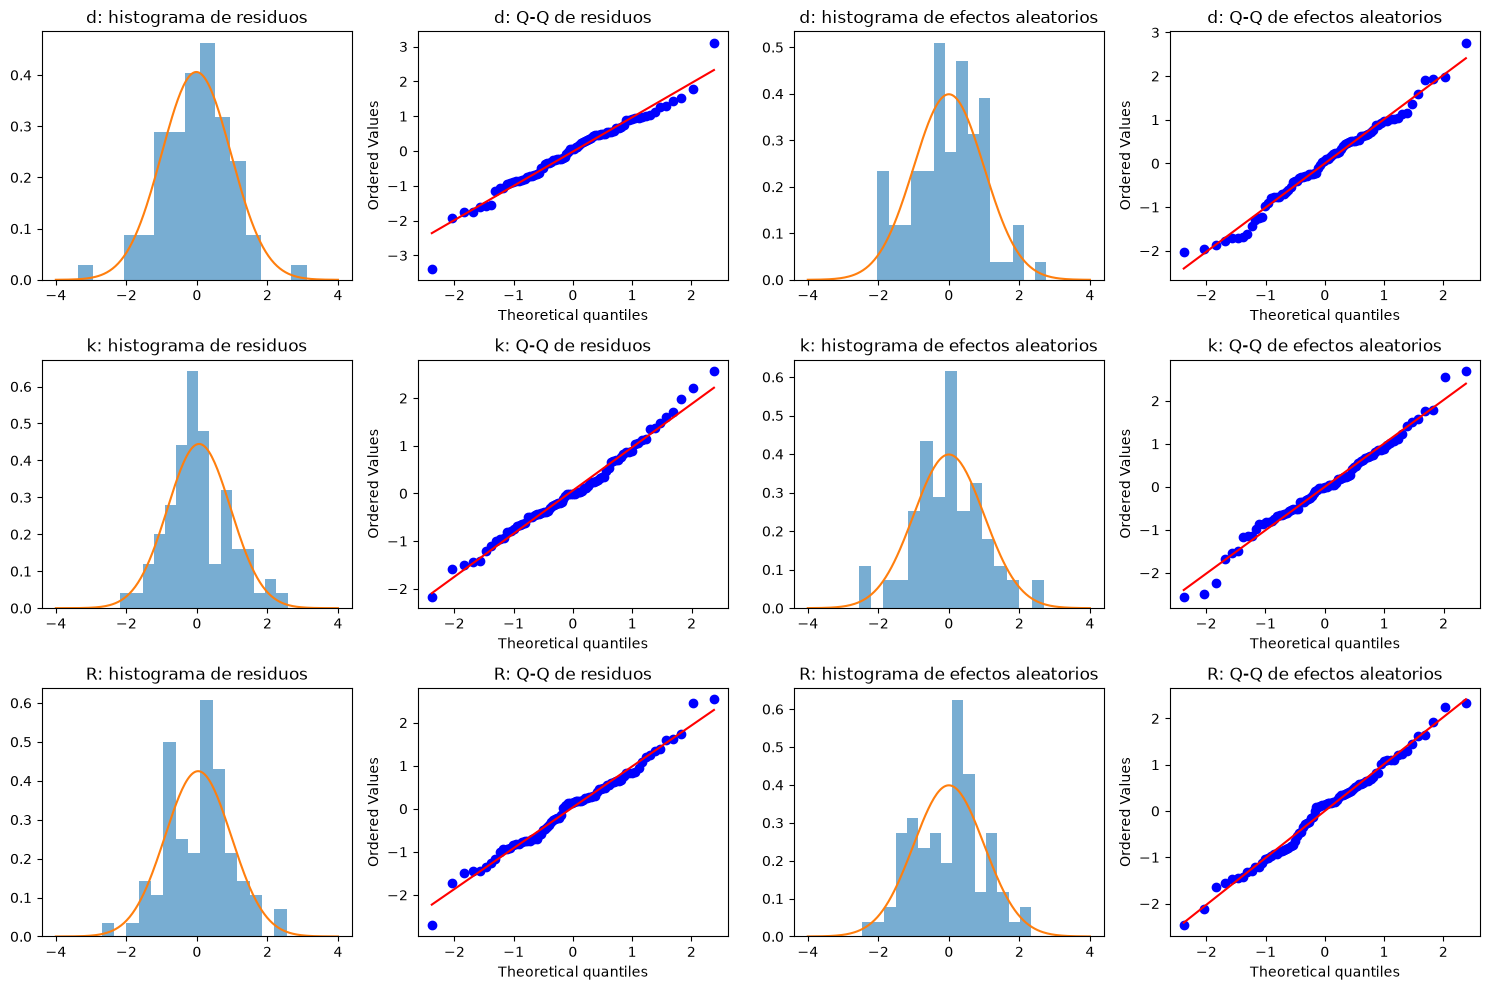

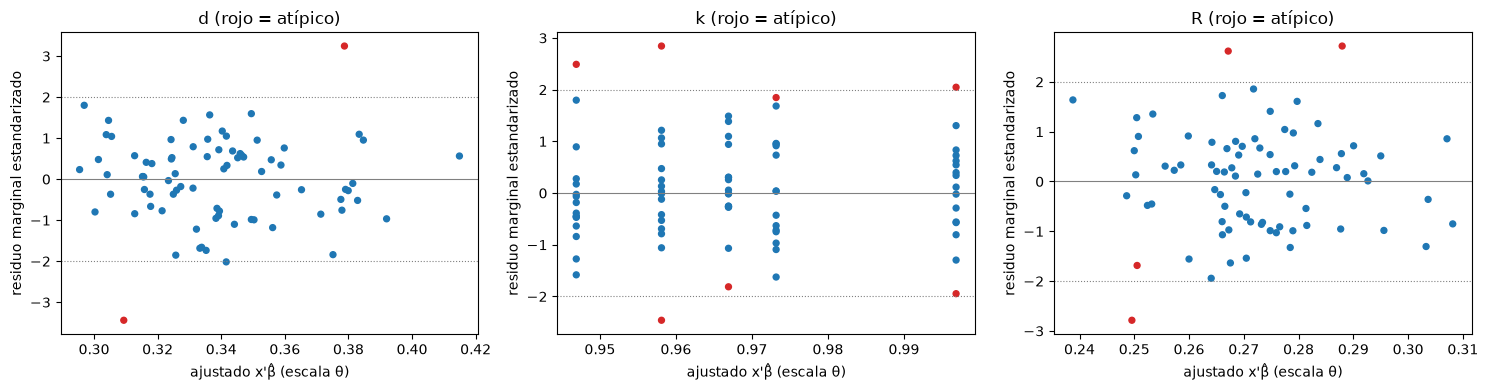

In [ ]:
# Diagnósticos del modelo elegido (Fay-Herriot agrupado)
# Tabla de verificación de supuestos, al estilo de Santillana
#
# QUÉ SE DIAGNOSTICA
#   residuos de nivel 1:  e_std = (θ_dir − θ̂_EBLUP) / √ψ
#   efectos aleatorios:   û = θ̂_EBLUP − x'β̂, estandarizados
#   residuos marginales:  r = (θ_dir − x'β̂) / √(σ²_u + ψ) ~ N(0, 1) bajo el modelo
#                         (para homocedasticidad: su varianza no debe depender
#                          del valor ajustado ni de las covariables)
#
# Todo se hace con todas las celdas y sin las degeneradas, porque una celda con
# θ en el borde (Milpa Alta 2022, d = 0) viola la normalidad por construcción.

from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.covariance import MinCovDet
import matplotlib.pyplot as plt

def harrison_mccabe(e, orden, frac=0.5, B=10000, rng=np.random.default_rng(20261012)):
    """HMC = Σ_{primera mitad} e² / Σ e², ordenando por 'orden'. Valores chicos
    indican más varianza en la segunda mitad. Valor p por simulación bajo H0."""
    e = np.asarray(e)[np.argsort(orden)]
    m = int(len(e) * frac)
    hmc = (e[:m] ** 2).sum() / (e ** 2).sum()
    sim = rng.standard_normal((B, len(e)))
    nulas = (sim[:, :m] ** 2).sum(1) / (sim ** 2).sum(1)
    return hmc, (np.sum(nulas <= hmc) + 1) / (B + 1)

def goldfeld_quandt(e, orden, drop=0.2):
    """F = varianza del tercio alto / varianza del tercio bajo (se descarta el
    20% central). Aplicado a residuos ya estandarizados, sin reajustar MCO."""
    e = np.asarray(e)[np.argsort(orden)]
    m = int(len(e) * (1 - drop) / 2)
    F = np.var(e[-m:]) / np.var(e[:m])
    return F, stats.f.sf(F, m, m)

def indice_condicion(X):
    """Convención de Belsley: columnas escaladas a norma 1, √(λ_máx / λ_mín)."""
    Xs = X / np.linalg.norm(X, axis=0)
    ev = np.linalg.eigvalsh(Xs.T @ Xs)
    return np.sqrt(ev.max() / ev.min())

filas_sup, diag_celdas = [], []
for p in ["d", "k", "R"]:
    cv = su.ESPECIFICACIONES[(p, "principal")]
    datos = base[base["param"] == p].sort_values(["alc", "anio_ref"]).reset_index(drop=True)
    res, info = su.ajustar_fh(datos, cv)
    o = res["theta_dir"].notna().to_numpy()
    r = res[o].copy()
    X = su.matriz_X(datos, cv)[o]
    r["e_std"] = (r["theta_dir"] - r["theta_eblup"]) / np.sqrt(r["psi"])
    r["u_hat"] = r["theta_eblup"] - r["sintetico"]
    r["u_std"] = (r["u_hat"] - r["u_hat"].mean()) / r["u_hat"].std(ddof=1)
    r["r_marg"] = (r["theta_dir"] - r["sintetico"]) / np.sqrt(info["s2u"] + r["psi"])

    for subconj, m in [("todas", np.ones(len(r), bool)),
                       ("sin_degeneradas", (r["tipo_celda"] != "degenerada").to_numpy())]:
        rr = r[m]
        # --- Normalidad ---------------------------------------------------------
        for sobre, v in [("residuos", rr["e_std"]), ("efectos_aleatorios", rr["u_std"])]:
            z = (v - v.mean()) / v.std(ddof=1)
            sw, ks, jb = stats.shapiro(v), stats.kstest(z, "norm"), stats.jarque_bera(v)
            filas_sup += [{"param": p, "celdas": subconj, "supuesto": "normalidad",
                           "sobre": sobre, "prueba": t, "estadistico": e_, "p_valor": pv}
                          for t, e_, pv in [("Shapiro-Wilk", sw.statistic, sw.pvalue),
                                            ("Kolmogorov-Smirnov", ks.statistic, ks.pvalue),
                                            ("Jarque-Bera", jb.statistic, jb.pvalue)]]
        # --- Homocedasticidad ---------------------------------------------------
        e, aj = rr["r_marg"].to_numpy(), rr["sintetico"].to_numpy()
        bp = het_breuschpagan(e, X[m])            # ¿e² depende de las covariables?
        gq = goldfeld_quandt(e, aj)               # ¿más varianza en ajustados altos?
        hm = harrison_mccabe(e, aj)
        filas_sup += [{"param": p, "celdas": subconj, "supuesto": "homocedasticidad",
                       "sobre": "residuos marginales", "prueba": t, "estadistico": e_, "p_valor": pv}
                      for t, e_, pv in [("Breusch-Pagan", bp[0], bp[1]),
                                        ("Goldfeld-Quandt", gq[0], gq[1]),
                                        ("Harrison-McCabe", hm[0], hm[1])]]

    # --- Atípicos: distancia de Mahalanobis robusta, por variable ----------------
    corte = stats.chi2.ppf(0.975, 1)
    for sobre, col in [("residuos", "e_std"), ("efectos_aleatorios", "u_std")]:
        mcd = MinCovDet(random_state=0).fit(r[[col]].to_numpy())
        r["d2_" + col] = mcd.mahalanobis(r[[col]].to_numpy())
        filas_sup.append({"param": p, "celdas": "todas", "supuesto": "atípicos", "sobre": sobre,
                          "prueba": "Mahalanobis robusta (MCD) > χ²₁(0.975); esperados ≈ 2",
                          "estadistico": int((r["d2_" + col] > corte).sum()), "p_valor": np.nan})
    r["atipico"] = (r["d2_e_std"] > corte) | (r["d2_u_std"] > corte)

    # --- Colinealidad --------------------------------------------------------------
    filas_sup.append({"param": p, "celdas": "todas", "supuesto": "colinealidad",
                      "sobre": "X con efectos de año", "prueba": "Índice de condición (Belsley) < 30",
                      "estadistico": indice_condicion(su.matriz_X(datos, cv)), "p_valor": np.nan})
    diag_celdas.append(r)

verif = pd.DataFrame(filas_sup)
verif["cumple_5pct"] = np.where(verif["p_valor"].isna(), "",
                                np.where(verif["p_valor"] > 0.05, "sí", "no"))
diag_celdas = pd.concat(diag_celdas, ignore_index=True)

pd.set_option("display.max_rows", 200)
print("Pruebas que NO se cumplen al 5%:")
print(verif[verif["cumple_5pct"] == "no"].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nSe cumplen {int((verif['cumple_5pct'] == 'sí').sum())} de "
      f"{int((verif['cumple_5pct'] != '').sum())} pruebas con valor p.\n")
print("Atípicos, colinealidad:")
print(verif[verif["supuesto"].isin(["atípicos", "colinealidad"])][["param", "supuesto", "sobre", "estadistico"]]
      .to_string(index=False, float_format=lambda x: f"{x:.2f}"))
print("\nCeldas marcadas como atípicas:")
print(diag_celdas.loc[diag_celdas["atipico"], ["param", "nombre", "anio_ref", "tipo_celda",
                                               "e_std", "u_std", "d2_e_std", "d2_u_std"]]
      .to_string(index=False, float_format=lambda x: f"{x:+.2f}"))

# --- Figuras: histogramas y Q-Q; residuos contra ajustados ---------------------
fig, ejes = plt.subplots(3, 4, figsize=(15, 10))
for i, p in enumerate(["d", "k", "R"]):
    r = diag_celdas[diag_celdas["param"] == p]
    for j, (col, tit) in enumerate([("e_std", "residuos"), ("u_std", "efectos aleatorios")]):
        ax = ejes[i, 2 * j]
        ax.hist(r[col], bins=15, density=True, alpha=0.6)
        xs = np.linspace(-4, 4, 200)
        ax.plot(xs, stats.norm.pdf(xs, r[col].mean(), r[col].std()))
        ax.set_title(f"{p}: histograma de {tit}")
        stats.probplot(r[col], dist="norm", plot=ejes[i, 2 * j + 1])
        ejes[i, 2 * j + 1].set_title(f"{p}: Q-Q de {tit}")
plt.tight_layout()
fig.savefig(RUTA_SALIDA / "fig_normalidad.png", dpi=200)

fig2, ejes2 = plt.subplots(1, 3, figsize=(15, 4))
for ax, p in zip(ejes2, ["d", "k", "R"]):
    r = diag_celdas[diag_celdas["param"] == p]
    ax.scatter(r["sintetico"], r["r_marg"], c=np.where(r["atipico"], "C3", "C0"), s=18)
    for y_ in (0, 2, -2):
        ax.axhline(y_, color="gray", lw=0.8, ls="-" if y_ == 0 else ":")
    ax.set_xlabel("ajustado x'β̂ (escala θ)"); ax.set_ylabel("residuo marginal estandarizado")
    ax.set_title(f"{p} (rojo = atípico)")
plt.tight_layout()
fig2.savefig(RUTA_SALIDA / "fig_residuos_vs_ajustados.png", dpi=200)
plt.show()

# --- Entregable 3 ------------------------------------------------------------------
verif.to_csv(RUTA_SALIDA / "tabla_verificacion_supuestos.csv", index=False, encoding="utf-8-sig")

- 53 de 54 pruebas se cumplen. La única que falla es **Jarque-Bera** sobre los residuos de d con todas las celdas (p = 0.028), y se explica por una sola observación: Milpa Alta 2022, la celda degenerada con d = 0, que es el punto aislado en −3.4 del Q-Q. Sin las degeneradas, la misma prueba da p = 0.46. Un θ en el borde viola la normalidad por construcción, y por eso existe la especificación de sensibilidad sin degeneradas.
- **Homocedasticidad**: las tres pruebas pasan en los tres parámetros, con y sin degeneradas. Las gráficas de residuos contra ajustados no muestran embudo ni tendencia.
- La gráfica de k no sirve para homocedasticidad. Como el modelo de k solo tiene efectos de año, x'β toma cinco valores y los puntos forman cinco columnas. En k, las pruebas formales son la evidencia; la gráfica no lo es.
- **Atípicos**. Son 2 y 1 en d, y 3 y 2 en R, en línea con los 2 esperados por azar. En k son 5 y 5, más de lo esperado. Pero ninguno pasa |2.9|, y con 80 normales estándar se esperan unas 3.6 celdas con |z| > 2. El MCD en una dimensión, con 80 datos, tiende a subestimar la escala y marcar de más. Lo importante: solo dos celdas pasan |3| en todo el modelo:

1. Milpa Alta 2022, la degenerada.
2. Tlalpan 2021, con residuo +3.11 en d y +2.54 en R. Que aparezca en los dos tiene sentido, porque R = d·k. Es la única celda normal con un residuo grande.

- **Colinealidad**: índices de condición entre 4.2 y 5.1, muy por debajo de 30.

Con esto el modelo elegido queda validado con el protocolo de Santillana.

## Benchmarking

1. Los totales de ciudad. Ajustar las estimaciones a la cifra oficial significa imponer, para cada parámetro y año:

$$\sum_a w_{at}\,\tilde p_{at} = p^{\text{CDMX}}_t$$

donde $w_{at}$ es la participación de la alcaldía en el denominador de cada parámetro:

Para d y R: los delitos ponderados con FAC_DEL que ocurrieron en esa alcaldía.
Para k: las denuncias ponderadas.

2. Una decisión de diseño. d, k y R se modelan por separado, así que en cada alcaldía $\hat R_a \neq \hat d_a \cdot \hat k_a$. Si ajusto los tres por separado, la identidad tampoco se cumple después del benchmarking. Hay dos opciones:

- Ajuste independiente: cada parámetro reproduce su total de ciudad y se reporta la discrepancia $\tilde R_a - \tilde d_a \tilde k_a$ como diagnóstico. Es más simple y transparente.
- Ajuste iterativo (raking): se alterna entre ajustar d y k a sus totales y recalcular R como su producto, hasta que las tres restricciones de ciudad se cumplan a la vez. La identidad se cumple por construcción. Es lo que “ajuste proporcional iterativo” sugiere en tu plan, pero R deja de ser un estimador propio.

Haré el independiente para las cifras principales y el iterativo como verificación, salvo que la aplicación necesite que R = d·k cuadre exactamente en cada alcaldía.

El orden de operaciones queda así: modelar en θ, regresar a proporción con la corrección de sesgo (p_modelo, que ya tienes), y después ajustar en proporción. El ECM después del ajuste suma el cuadrado del cambio, $(\tilde p - \hat p)^2$, que se reporta aparte.

In [ ]:
# Totales de ciudad y pesos por alcaldía para el benchmarking
#
# Para cada parámetro y año, el benchmarking impone
#       Σ_a w_at · p̃_at = p_t^CDMX
# con w_at = participación de la alcaldía en el DENOMINADOR del parámetro:
#   d y R: delitos ponderados ocurridos en la alcaldía
#   k:     denuncias ponderadas ocurridas en la alcaldía
#
# Insumos: los parquet del día 2 y la reconstrucción de FAC_DEL_AJ del día 5
# (celdas 1 y 3 de 05_estimadores_directos), sin cambios de lógica.

inc      = pd.read_parquet(RUTA_DATOS / "envipe_incidentes.parquet")
personas = pd.read_parquet(RUTA_DATOS / "envipe_personas.parquet")

# --- 1. Reconstruir FAC_DEL_AJ (día 5, celdas 1 y 3) ---------------------------
# c_a = población CONAPO 18+ del año de referencia / población 18+ que estima la
# ENVIPE, por alcaldía de RESIDENCIA. Fuera de la CDMX, c = 1.
pob_envipe = (personas[personas["ENT_RES"] == "09"]
              .groupby(["anio_envipe", "MUN_RES"])["FAC_ELE"].sum()
              .rename("pob_envipe").reset_index()
              .rename(columns={"MUN_RES": "alc_res"}))
pob_envipe["anio_ref"] = pob_envipe["anio_envipe"] - 1
pob_envipe = pob_envipe.merge(
    maestro[["cve_mun", "anio_ref", "pob_18_conapo"]].rename(columns={"cve_mun": "alc_res"}),
    on=["alc_res", "anio_ref"], how="inner", validate="1:1")
assert len(pob_envipe) == 80
pob_envipe["c_aj"] = pob_envipe["pob_18_conapo"] / pob_envipe["pob_envipe"]

inc = inc.drop(columns="c_aj", errors="ignore").merge(
    pob_envipe[["anio_envipe", "alc_res", "c_aj"]],
    on=["anio_envipe", "alc_res"], how="left", validate="m:1")
inc["c_aj"] = inc["c_aj"].fillna(1.0)
inc["FAC_DEL_AJ"] = inc["FAC_DEL"] * inc["c_aj"]
inc["anio_ref"] = inc["anio_envipe"] - 1
inc["todos"] = True

# --- 2. Denominadores y numeradores ponderados por alcaldía --------------------
DEF = {"d": ("denuncio", "todos"), "k": ("carpeta", "denuncio"), "R": ("carpeta", "todos")}
universo = ~inc["excl_vandalismo"]
alc16 = universo & inc["alc_ocu"].isin(maestro["cve_mun"].unique())

filas = []
for p, (num, den) in DEF.items():
    for peso in ["FAC_DEL_AJ", "FAC_DEL"]:
        g = (inc[alc16]
             .assign(N=lambda x: x[peso] * x[den], Y=lambda x: x[peso] * x[num])
             .groupby(["alc_ocu", "anio_ref"])[["N", "Y"]].sum().reset_index())
        filas.append(g.assign(param=p, factor=peso))
pesos_alc = (pd.concat(filas, ignore_index=True)
             .rename(columns={"alc_ocu": "alc", "N": "N_ponderado", "Y": "Y_ponderado"}))

# --- 3. Verificación: con FAC_DEL_AJ se reproducen tus directos ----------------
# Si esto falla, la reconstrucción del factor no es la del día 5 y no seguimos.
chk = (pesos_alc[pesos_alc["factor"] == "FAC_DEL_AJ"]
       .assign(p_recalc=lambda x: x["Y_ponderado"] / x["N_ponderado"])
       .merge(base[["alc", "anio_ref", "param", "est"]], on=["alc", "anio_ref", "param"],
              validate="1:1"))
dif = (chk["p_recalc"] - chk["est"]).abs().max()
print(f"Máx |p recalculada − directo v2| en las 240 celdas: {dif:.1e}")
assert dif < 1e-10, "La reconstrucción de FAC_DEL_AJ no reproduce los directos"

# --- 4. Metas de ciudad ---------------------------------------------------------
# (a) consistente: factor ajustado, 16 alcaldías
# (b) oficial: factor original, CDMX por ocurrencia INCLUIDA la alcaldía 999
#     (el dominio con el que reprodujiste al INEGI en los días 2 y 5)
metas = []
for p, (num, den) in DEF.items():
    a = pesos_alc[(pesos_alc["param"] == p) & (pesos_alc["factor"] == "FAC_DEL_AJ")]
    cons = a.groupby("anio_ref")[["Y_ponderado", "N_ponderado"]].sum()
    dom = universo & inc["cdmx_ocu"]
    of = (inc[dom].assign(Y=lambda x: x["FAC_DEL"] * x[num], N=lambda x: x["FAC_DEL"] * x[den])
          .groupby("anio_ref")[["Y", "N"]].sum())
    metas.append(pd.DataFrame({
        "param": p,
        "p_consistente": cons["Y_ponderado"] / cons["N_ponderado"],
        "p_oficial": of["Y"] / of["N"]}).reset_index())
metas = pd.concat(metas, ignore_index=True)
metas["dif_pp"] = 100 * (metas["p_oficial"] - metas["p_consistente"])

# Control: la meta oficial debe ser tu tabla de ciudad (días 2 y 5)
OFICIAL = {"d": [11.20, 11.83, 11.09, 10.81, 9.97],
           "k": [66.07, 65.92, 67.05, 64.64, 68.46]}
for p, v in OFICIAL.items():
    m_ = metas[metas["param"] == p].sort_values("anio_ref")
    assert np.allclose(100 * m_["p_oficial"], v, atol=0.006), f"La meta oficial de {p} no cuadra"
print("Control OK: la meta oficial reproduce las cifras de ciudad del INEGI.\n")

# --- 5. ¿Qué tan lejos queda el modelo de cada meta? (antes de ajustar) ---------
# p_modelo: EBLUP agrupado regresado a proporción con corrección de sesgo (día 10)
mod = (eblup_d10.query("modelo == 'agrupado' and especificacion == 'principal'")
       [["alc", "anio_ref", "param", "p_modelo"]])
w = (pesos_alc[pesos_alc["factor"] == "FAC_DEL_AJ"]
     .merge(mod, on=["alc", "anio_ref", "param"], validate="1:1"))
agregado = (w.assign(wp=w["N_ponderado"] * w["p_modelo"])
            .groupby(["param", "anio_ref"])[["wp", "N_ponderado"]].sum())
agregado = (agregado["wp"] / agregado["N_ponderado"]).rename("p_modelo_agregado").reset_index()
metas = metas.merge(agregado, on=["param", "anio_ref"])
metas["factor_consistente"] = metas["p_consistente"] / metas["p_modelo_agregado"]
metas["factor_oficial"] = metas["p_oficial"] / metas["p_modelo_agregado"]

print("Metas de ciudad y factor de ajuste que haría falta (1 = el modelo ya cuadra):")
print(metas.assign(**{c: 100 * metas[c] for c in ["p_consistente", "p_oficial", "p_modelo_agregado"]})
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

pesos_alc.to_parquet(RUTA_SALIDA / "pesos_alcaldia_benchmark.parquet", index=False)
metas.to_csv(RUTA_SALIDA / "metas_ciudad_benchmark.csv", index=False, encoding="utf-8-sig")

Máx |p recalculada − directo v2| en las 240 celdas: 3.3e-16
Control OK: la meta oficial reproduce las cifras de ciudad del INEGI.

Metas de ciudad y factor de ajuste que haría falta (1 = el modelo ya cuadra):
 anio_ref param  p_consistente  p_oficial  dif_pp  p_modelo_agregado  factor_consistente  factor_oficial
     2020     d        11.3339    11.2002 -0.1337            11.2131              1.0108          0.9989
     2021     d        11.6166    11.8277  0.2111            11.4373              1.0157          1.0341
     2022     d        11.4136    11.0916 -0.3220            11.1222              1.0262          0.9973
     2023     d        10.6549    10.8083  0.1534            10.7111              0.9948          1.0091
     2024     d         9.9511     9.9707  0.0196            10.0429              0.9909          0.9928
     2020     k        66.3553    66.0713 -0.2840            66.8108              0.9932          0.9889
     2021     k        66.2259    65.9213 -0.3046       

Las dos verificaciones pasan. La reconstrucción de FAC_DEL_AJ reproduce tus 240 directos hasta 3.3e-16, y la meta oficial reproduce al INEGI.

El modelo ya respeta el total de ciudad sin que nadie se lo pida. Con la meta consistente, el factor de ajuste queda entre 0.982 y 1.026: el modelo se desvía del total de ciudad en a lo sumo 2.6%. En puntos, la mayor diferencia es 0.32 en d (2022) y 1.23 en k (2024), contra errores estándar de ciudad de alrededor de 0.9 puntos en d y 3 a 4 en k. Todas las desviaciones caben dentro del error muestral de la propia cifra de ciudad. El modelo se ajustó alcaldía por alcaldía y nunca vio el total; que lo reproduzca es una validación externa. La respuesta a “¿contradices al INEGI?” es entonces: no, y el benchmarking solo cierra una diferencia que ya era menor que el error de la propia cifra oficial.

La meta oficial no sirve como meta principal, y k 2023 lo demuestra. Ahí la diferencia entre las dos metas es de 2.4 puntos, mucho más que la del factor (0.81 en tu día 5). El resto viene de los incidentes sin alcaldía. Ajustar a la cifra oficial bajaría k 3.8% en las 16 alcaldías por una diferencia de definición, no por un error del modelo.

Recomiendo la meta consistente como principal y la oficial como sensibilidad. La meta consistente difiere de la cifra publicada por el INEGI solo por el ajuste a CONAPO y la exclusión de incidentes sin alcaldía; ambas diferencias se documentan en la sección de datos.

### Benchmarking y la prueba de consistencia

In [ ]:
# Benchmarking proporcional y prueba de consistencia R = d·k
#
# ORDEN DE OPERACIONES (el que importa defender)
#   1. Modelar en θ = arcsen√p                        
#   2. Regresar a proporción con corrección de sesgo:
#        p̂ = ½ − ½·cos(2θ̂)·exp(−2·ECM)              
#   3. Ajustar en PROPORCIÓN, nunca en θ:
#        p̃_at = p̂_at · c_t,   c_t = p_t^CDMX / Σ_a w_at p̂_at
#      con w_at = N_at / Σ_a N_at (delitos para d y R; denuncias para k).
#      Un solo factor por parámetro y año: con una restricción por año, el
#      ajuste proporcional iterativo converge en un paso.
#
#   ¿Por qué no en θ? La restricción es lineal en p (un promedio ponderado),
#   y arcsen√· no es lineal: multiplicar θ por una constante no conserva el
#   promedio ponderado de las p.
#
# ECM DESPUÉS DEL AJUSTE
#   ECM(p̃) ≈ ECM(p̂) + (p̃ − p̂)²   (el ajuste agrega un sesgo conocido)
#   Los intervalos del bootstrap se escalan por el mismo factor c_t.

fin = (eblup_d10.query("modelo == 'agrupado' and especificacion == 'principal'")
       [["alc", "nombre", "anio_ref", "param", "p_directo", "p_modelo", "ecm_p",
         "ic95_inf", "ic95_sup", "cv_modelo"]]
       .merge(pesos_alc.loc[pesos_alc["factor"] == "FAC_DEL_AJ",
                            ["alc", "anio_ref", "param", "N_ponderado"]],
              on=["alc", "anio_ref", "param"], validate="1:1")
       .merge(metas[["param", "anio_ref", "p_consistente", "p_oficial"]],
              on=["param", "anio_ref"], validate="m:1"))

# --- 1. Ajuste proporcional, a las dos metas -----------------------------------
for meta in ["consistente", "oficial"]:
    agregado = (fin.assign(wp=fin["N_ponderado"] * fin["p_modelo"])
                .groupby(["param", "anio_ref"])[["wp", "N_ponderado"]].transform("sum"))
    factor = fin["p_" + meta] / (agregado["wp"] / agregado["N_ponderado"])
    fin["p_bench_" + meta] = fin["p_modelo"] * factor
    fin["factor_" + meta] = factor

# --- 2. ECM, CV e intervalos (meta principal: consistente) ---------------------
fin["ecm_p_bench"] = fin["ecm_p"] + (fin["p_bench_consistente"] - fin["p_modelo"]) ** 2
fin["cv_bench"] = np.sqrt(fin["ecm_p_bench"]) / fin["p_bench_consistente"]
fin["ic95_inf_bench"] = fin["ic95_inf"] * fin["factor_consistente"]
fin["ic95_sup_bench"] = (fin["ic95_sup"] * fin["factor_consistente"]).clip(upper=1)

# --- 3. Verificaciones ------------------------------------------------------------
chk = (fin.assign(wp=fin["N_ponderado"] * fin["p_bench_consistente"])
       .groupby(["param", "anio_ref"])
       .apply(lambda g: g["wp"].sum() / g["N_ponderado"].sum(), include_groups=False)
       .rename("p_agregado_bench").reset_index()
       .merge(metas[["param", "anio_ref", "p_consistente"]], on=["param", "anio_ref"]))
print(f"Máx |agregado ajustado − meta|: {(chk['p_agregado_bench'] - chk['p_consistente']).abs().max():.1e}")
print(f"Celdas con p ajustada > 1: {(fin['p_bench_consistente'] > 1).sum()}")

print("\nCambio relativo por el ajuste, |p̃/p̂ − 1|:")
for meta in ["consistente", "oficial"]:
    c = (fin["p_bench_" + meta] / fin["p_modelo"] - 1).abs()
    print(f"  meta {meta:12s}", c.groupby(fin["param"]).agg(["median", "max"])
          .round(4).to_dict("index"))

print("\nCV del modelo contra CV después del ajuste (mediana y máximo):")
print(fin.groupby("param")[["cv_modelo", "cv_bench"]].agg(["median", "max"])
      .to_string(float_format=lambda x: f"{x:.4f}"))

# --- 4. Prueba de consistencia R̃ contra d̃·k̃ -----------------------------------
# En los directos, R = d·k es una identidad algebraica (día 5). Aquí no: cada
# parámetro tiene su propio modelo y su propio encogimiento. La discrepancia se
# mide en puntos, en términos relativos y en errores estándar de R̃.
piv = fin.pivot_table(index=["alc", "nombre", "anio_ref"], columns="param",
                      values="p_bench_consistente")
piv["dk"] = piv["d"] * piv["k"]
piv["dif_R_dk_pp"] = 100 * (piv["R"] - piv["dk"])
piv["dif_rel"] = piv["R"] / piv["dk"] - 1
ecm_R = fin[fin["param"] == "R"].set_index(["alc", "nombre", "anio_ref"])["ecm_p_bench"]
piv["dif_en_ee_R"] = (piv["R"] - piv["dk"]) / np.sqrt(ecm_R)

print("\nConsistencia R̃ contra d̃·k̃ (80 celdas):")
print(piv[["dif_R_dk_pp", "dif_rel", "dif_en_ee_R"]].describe()
      .loc[["mean", "50%", "min", "max"]].to_string(float_format=lambda x: f"{x:+.4f}"))
print(f"Celdas con |R̃ − d̃·k̃| > 1 ee de R̃: {(piv['dif_en_ee_R'].abs() > 1).sum()} de 80"
      f"  (bajo normalidad se esperarían ≈ 25 si fueran independientes)")
print("\nLas 5 celdas con mayor discrepancia:")
print(piv.reindex(piv["dif_en_ee_R"].abs().sort_values(ascending=False).index).head(5)
      [["d", "k", "R", "dk", "dif_R_dk_pp", "dif_en_ee_R"]]
      .to_string(float_format=lambda x: f"{x:+.4f}"))

# --- 5. Entregable 4 ----------------------------------------------------------------
estimaciones_finales = fin[["param", "alc", "nombre", "anio_ref", "p_directo", "p_modelo",
                            "p_bench_consistente", "p_bench_oficial", "factor_consistente",
                            "ecm_p_bench", "cv_bench", "ic95_inf_bench", "ic95_sup_bench"]]
estimaciones_finales.to_parquet(RUTA_SALIDA / "estimaciones_finales_benchmark.parquet", index=False)
piv.reset_index().to_csv(RUTA_SALIDA / "consistencia_R_dk.csv", index=False, encoding="utf-8-sig")
print(f"\nestimaciones_finales: {estimaciones_finales.shape} → guardado")

Máx |agregado ajustado − meta|: 1.1e-16
Celdas con p ajustada > 1: 0

Cambio relativo por el ajuste, |p̃/p̂ − 1|:
  meta consistente  {'R': {'median': 0.0146, 'max': 0.024}, 'd': {'median': 0.0108, 'max': 0.0262}, 'k': {'median': 0.0068, 'max': 0.0177}}
  meta oficial      {'R': {'median': 0.0078, 'max': 0.0379}, 'd': {'median': 0.0072, 'max': 0.0341}, 'k': {'median': 0.0111, 'max': 0.0379}}

CV del modelo contra CV después del ajuste (mediana y máximo):
      cv_modelo        cv_bench       
         median    max   median    max
param                                 
R        0.1639 0.2421   0.1621 0.2388
d        0.1198 0.1908   0.1204 0.1885
k        0.0904 0.1052   0.0918 0.1048

Consistencia R̃ contra d̃·k̃ (80 celdas):
param  dif_R_dk_pp  dif_rel  dif_en_ee_R
mean       -0.1734  -0.0166      -0.1293
50%        -0.0719  -0.0089      -0.0587
min        -1.7614  -0.1942      -1.4434
max        +1.1539  +0.1553      +0.9906
Celdas con |R̃ − d̃·k̃| > 1 ee de R̃: 5 de 80  (bajo normal

## Método

### Diseño muestral y estimador directo

Los datos provienen de la ENVIPE 2021–2025, que capta delitos ocurridos entre 2020 y 2024. La encuesta usa un diseño probabilístico estratificado y por conglomerados, con estratos de diseño (`EST_DIS`) y unidades primarias de muestreo (`UPM_DIS`). La unidad de análisis es el incidente delictivo, expandido con el factor `FAC_DEL` y excluyendo vandalismo. Como en Santillana et al. (2023), el factor se calibró a la población de 18 años y más de CONAPO por alcaldía de residencia; las cifras de ciudad reproducen las del INEGI con el factor original.

Para la alcaldía $a$ de ocurrencia y el año $t$, los tres parámetros se estiman como razones ponderadas:

$$
\hat d_{at} = \frac{\sum_i w_i\,D_i}{\sum_i w_i}, \qquad
\hat k_{at} = \frac{\sum_i w_i\,C_i}{\sum_i w_i\,D_i}, \qquad
\hat R_{at} = \frac{\sum_i w_i\,C_i}{\sum_i w_i}
$$

donde $D_i$ indica denuncia y $C_i$ inicio de carpeta. Como ningún incidente tiene carpeta sin denuncia, $\hat R = \hat d\,\hat k$ por identidad. La varianza se obtiene por linealización de Taylor, con varianza entre UPM dentro de cada estrato.

### Transformación y varianza de trabajo

Las estimaciones se modelan en la escala $\theta = \arcsin\sqrt{p}$, que estabiliza la varianza de una proporción. La varianza muestral se fija como

$$
\psi_{at} = \frac{1}{4\,\tilde n_{at}}, \qquad \tilde n_{at} = \frac{n_{at}}{\widetilde{\text{deff}}}
$$

con un efecto de diseño suavizado por parámetro (1.48 a 1.59). Suavizar evita varianzas nulas o inestables en celdas pequeñas, y el modelo de área supone $\psi$ conocida.

### Modelo de área

El modelo base es el de Fay y Herriot (1979), con las 80 celdas alcaldía-año agrupadas:

$$
\hat\theta_{at} = \mathbf{x}_{at}'\boldsymbol\beta + u_{at} + e_{at}, \qquad
u_{at}\sim N(0,\sigma^2_u), \quad e_{at}\sim N(0,\psi_{at})
$$

El vector $\mathbf{x}_{at}$ incluye efectos fijos de año y covariables elegidas por todos los subconjuntos. El predictor combina el directo con la predicción sintética:

$$
\tilde\theta_{at} = \gamma_{at}\,\hat\theta_{at} + (1-\gamma_{at})\,\mathbf{x}_{at}'\hat{\boldsymbol\beta},
\qquad \gamma_{at} = \frac{\hat\sigma^2_u}{\hat\sigma^2_u + \psi_{at}}
$$

### Extensión temporal

Para compartir información entre años de una misma alcaldía se ajustó el modelo de Rao y Yu (1994):

$$
\hat\theta_{at} = \mathbf{x}_{at}'\boldsymbol\beta + u_a + v_{at} + e_{at}, \qquad
v_{at} = \rho\,v_{a,t-1} + \varepsilon_{at}
$$

con $u_a\sim N(0,\sigma^2_1)$ persistente y $\varepsilon_{at}\sim N(0,\sigma^2_2)$. Dentro de cada alcaldía, la covarianza es

$$
\mathbf{V}_a = \sigma^2_1\,\mathbf{J}_5 + \sigma^2_2\,\boldsymbol\Gamma(\rho) + \operatorname{diag}(\boldsymbol\psi_a),
\qquad \Gamma_{ts} = \frac{\rho^{|t-s|}}{1-\rho^2}
$$

El Fay-Herriot agrupado ($\sigma^2_1 = 0$, $\rho = 0$) y el modelo con efecto de alcaldía ($\sigma^2_2 = 0$) son casos particulares, lo que permite compararlos directamente.

### Estimación de las varianzas

Las componentes de varianza se estimaron por máxima verosimilitud restringida (REML) con scoring de Fisher; $\rho$ se estimó por verosimilitud perfil. Cuando la REML cae en la frontera ($\hat\sigma^2 = 0$), se usa la versión ajustada de Li y Lahiri (2010), que maximiza $\ell_{\text{REML}} + \log\sigma^2_u$. Para saber qué tan grande podría ser la variación persistente que los datos no detectan, se calculó una cota superior al 95% de $\sigma^2_1$ por verosimilitud perfil, usando la mezcla $\tfrac12\chi^2_0 + \tfrac12\chi^2_1$ que corresponde a un parámetro en la frontera.

### Error cuadrático medio

El ECM en escala $\theta$ es la aproximación de segundo orden de Prasad y Rao (1990), generalizada por Das, Jiang y Rao (2004):

$$
\operatorname{ECM}(\tilde\theta_{at}) \approx g_1 + g_2 + 2g_3
$$

$g_1$ es la incertidumbre con varianzas conocidas, $g_2$ la de estimar $\boldsymbol\beta$ y $g_3$ la de estimar las varianzas. Para el modelo elegido, el ECM en proporción y los intervalos al 95% se obtuvieron por bootstrap paramétrico (González-Manteiga et al., 2008), con $B = 1{,}000$ y reajuste completo en cada réplica. La proporción se recupera con corrección de sesgo:

$$
\tilde p_{at} = \tfrac12 - \tfrac12\cos(2\tilde\theta_{at})\,e^{-2\,\operatorname{ECM}(\tilde\theta_{at})}
$$

### Elección del modelo

La estructura de covarianza se eligió por el AIC de la REML, que es comparable porque los modelos comparten la misma matriz $\mathbf{X}$. Entre las estructuras que los datos sostienen, se comparó la raíz del ECM relativo, leída junto con el peso que reciben los datos de cada alcaldía y el rango de las estimaciones entre alcaldías. Un ECM bajo obtenido con encogimiento total hacia la predicción sintética no indica precisión, sino variación eliminada.

### Benchmarking

Las estimaciones finales se ajustaron en proporción, después de la retransformación, para que su promedio ponderado reproduzca el total de la ciudad:

$$
\tilde p^{\,B}_{at} = \tilde p_{at}\cdot\frac{p^{\text{CDMX}}_t}{\sum_a w_{at}\,\tilde p_{at}}
$$

Los pesos $w_{at}$ son la participación ponderada de la alcaldía en el denominador del parámetro: delitos para $d$ y $R$, denuncias para $k$. La meta principal usa el mismo factor y las mismas 16 alcaldías; la cifra publicada por el INEGI, que incluye incidentes sin alcaldía, se usa como sensibilidad. El ECM ajustado suma el cuadrado del cambio, $(\tilde p^{\,B} - \tilde p)^2$.

### Criterios de confiabilidad

Se reportan dos criterios. El del INEGI clasifica por coeficiente de variación: alta precisión debajo de 15%, moderada entre 15% y 30%, y baja arriba de 30%. El de Buil-Gil et al. (2021) clasifica por la raíz del ECM relativo: confiable hasta 25%, con cautela entre 25% y 50%, y no publicable arriba de 50%.

# Nota de escenarios: qué implica el resultado para las hipótesis

## En qué escenario caímos

Escenario 3, con matices. Ninguno de los cinco métodos encuentra variación persistente entre alcaldías que no expliquen las covariables, en ninguno de los tres parámetros. La variación que el Fay-Herriot agrupado atribuía a las alcaldías es, en su mayoría, variación de un año a otro dentro de cada alcaldía, sin persistencia.

El resultado nulo tiene tres alcances distintos:

| Parámetro | Variación persistente estimada | Cota superior al 95% (brecha entre la alcaldía más alta y la más baja) | Lectura |
|---|---|---|---|
| `d` | 0 con covariables; ~2.5 puntos sin ellas | 3.9 puntos con covariables; 6.2 sin ellas | Variación modesta, explicada por las covariables |
| `k` | 0 | 19.5 puntos | La encuesta no tiene potencia para medirla |
| `R` | 0 con covariables; ~1.6 puntos sin ellas | 3.6 con covariables; 4.7 sin ellas | Variación acotada |

## H1. La propensión a denunciar varía entre alcaldías más que la victimización

**No se sostiene con la estimación puntual y no se puede rechazar formalmente.**

Sin covariables, la variación persistente de `d` implica una razón entre la alcaldía más alta y la más baja de alrededor de 1.26 a 1 (aproximación por método delta alrededor del nivel de ciudad, 11%). Es menor que el 1.5 a 1 del indicio de victimización. Pero la cota superior permite hasta 1.8 a 1, así que los datos no descartan que la propensión varíe más.

**El indicio no era una comparación justa.** El 1.5 a 1 de victimización sale de estimaciones directas, que incluyen error muestral. Hoy vimos que ese ruido infla los rangos entre alcaldías: en `d`, el rango directo era 17.5 puntos y el modelado 5.4. Una prueba limpia de H1 requiere modelar la victimización con el mismo tratamiento, para comparar varianza de señal contra varianza de señal.

**Lo que sí se puede afirmar.** Las diferencias en `d` entre alcaldías existen, son pequeñas y las explican tres covariables: SESNSP, rezago a 7 días y canal digital. No queda variación propia de cada alcaldía después de ellas.

## H3. Al corregir por propensión, el orden de prioridad cambia de forma material

**Pendiente de verificar con el mapa corregido, pero la expectativa es que no.**

Si `R` varía a lo sumo 2 a 1 entre alcaldías (cota) y con mayor probabilidad alrededor de 1.25 a 1 (estimación puntual), dividir la tasa de carpetas entre `R̃` no puede reordenar mucho un mapa que varía 3.5 a 1. El orden del mapa corregido seguirá dominado por el de las carpetas. La prueba es la correlación de Spearman entre ambos órdenes, y cuántas alcaldías se mueven más de dos posiciones.

**El indicio de Cuauhtémoc tiene otra explicación.** Cuauhtémoc registra 3.7 veces la tasa de Iztapalapa con menos hogares victimizados porque las carpetas se cuentan por lugar de **ocurrencia** y la victimización de hogares por lugar de **residencia**. Cuauhtémoc recibe delitos contra personas que no viven ahí (población flotante, documentada en la celda 18 del día 4). Eso es una diferencia de geografía, no de propensión.

**Consecuencia para el escrito.** Si la brecha 3.7 a 1 de carpetas contra 1.5 a 1 de victimización no la explica la propensión, la explica principalmente la diferencia entre ocurrencia y residencia. Es un hallazgo en sí mismo: la desigualdad del mapa oficial refleja dónde ocurren los delitos, no quién decide denunciarlos.

## H2 y H4, de paso

- **H2** queda en tensión con el resultado. Las covariables que explican la variación de `d` incluyen el SESNSP, que mide el nivel de delito registrado, con signo negativo. El eje socioeconómico no entró en la selección. Así como está redactada ("no por el nivel de delito"), la evidencia va en contra.
- **H4** no se ve afectada por lo de hoy, y el canal digital la respalda dos veces: redujo el rezago en los días 6 a 8, y hoy sale como la covariable más fuerte de `d` (t = +2.82).

## Qué conserva intacta la aportación

La descomposición **por etapa** no depende de la geografía:

- De cada 100 delitos se denuncian alrededor de 11 (`d`).
- De cada 100 denuncias, alrededor de 66 llegan a carpeta (`k`).
- La pérdida institucional, una de cada tres denuncias, ocurre en todas las alcaldías. Aun en el extremo superior que permite la cota, la mejor alcaldía quedaría alrededor de 76%, lejos del 100% que exige el CNPP.

La pregunta "¿por qué la fracción varía entre alcaldías?" se responde así: varía poco, y lo que varía lo explican covariables observables. La aportación pasa a ser medir cuánto se pierde en cada etapa y mostrar que la barrera institucional es generalizada.

# Nota de decisiones: Rao-Yu, comparación de métodos, diagnósticos y benchmarking

## Resumen

El Fay-Herriot agrupado del día 10 se mantiene como modelo principal. Ninguna estructura alternativa lo mejora en verosimilitud, y las que reportan menor ECM lo logran eliminando variación. No hay efecto persistente por alcaldía detectable en ningún parámetro. El modelo reproduce el total de ciudad sin forzarlo, pasa 53 de 54 pruebas de supuestos, y sus estimaciones de `d`, `k` y `R` son consistentes entre sí.

## Modelo intermedio: efecto de alcaldía (16 efectos en lugar de 80)

| | σ²_u por celda (día 10) | σ²_u persistente, con covariables | σ²_u persistente, sin covariables | Peso del área (con / sin) |
|---|---|---|---|---|
| `d` | 0.000289 | 0 (frontera) | 0.00022 | 0 / 0.33 |
| `k` | 0.00439 | 0.00012 | 0.00012 | 0.036 |
| `R` | 0.000473 | 0.000036 | 0.000172 | 0.077 / 0.29 |

La expectativa de γ ≈ 0.30 en `d` y 0.49 en `k` suponía que σ²_u se mantenía mientras ψ bajaba a la quinta parte. Lo que bajó fue σ²_u.

## Verificación independiente

- **Momentos.** A nivel celda, la dispersión observada excede a ψ entre 32% y 56%. A nivel media de alcaldía, la razón es 1.10, 1.18 y 1.04, indistinguible de 1 con 16 medias (error relativo ≈ 37%).
- **Permutación.** La correlación intraclase de los residuos del día 10 es −0.12, −0.01 y −0.07 (p = 0.93, 0.51, 0.78). El agrupado no dejaba fuera un efecto persistente, así que su ECM no era optimista por el supuesto de independencia entre años.
- **Dos componentes.** Con alcaldía y celda juntas, la parte persistente se va a cero con covariables en los tres parámetros. Sin covariables: 19% en `d` (p = 0.29), 12% en `R` (p = 0.36), 0 en `k`.
- **REML ajustada.** En `k`, sin estar en la frontera, multiplica σ²_u por 19 (de 0.00012 a 0.0023). La verosimilitud es plana y la penalización domina. **Decisión:** en los modelos de 16 alcaldías no se aplica la regla del día 10; REML es la principal y la ajustada es sensibilidad.
- **Correlación muestral entre años.** Si los errores muestrales de una alcaldía se correlacionan positivamente entre años (mismo marco y estratos), la varianza real de la media quinquenal es mayor que Σψ/T², y el exceso persistente sería todavía menor. El supuesto de independencia juega en contra de encontrar señal.

## Rao-Yu

σ²_1 = 0 en los tres parámetros. ρ no está identificado: con covariables, su intervalo cubre de −0.9 a +0.9. La varianza marginal del componente AR (0.000347, 0.00436, 0.000593) reproduce la σ²_u del agrupado. Programado en Python con el mismo motor de REML de K componentes; ρ por verosimilitud perfil. No se calculó su ECM por bootstrap porque no quedó elegido.

## Comparación de métodos

| Método | ΔAIC (`d` / `k` / `R`) | RRMSE mediano | Peso del área | Rango entre alcaldías (puntos) |
|---|---|---|---|---|
| Directo | — | 0.278 / 0.178 / 0.332 | 1 | 17.5 / 54.1 / 15.2 |
| FH agrupado | 0 / 0 / 0 | 0.128 / 0.095 / 0.170 | 0.11 / 0.20 / 0.17 | 5.4 / 11.3 / 3.1 |
| FH con efecto de alcaldía | 0.6 / 2.4 / 1.9 | 0.079 / 0.055 / 0.114 | 0 / 0.04 / 0.08 | 5.1 / 0.7 / 2.2 |
| Rao-Yu | 3.6 / 3.9 / 2.2 | 0.134 / 0.095 / 0.175 | 0.21 / 0.16 / 0.37 | 5.3 / 11.3 / 3.5 |

**Criterio:** primero la estructura de covarianza por AIC de REML (X común); después la precisión, leída junto al peso y al rango. El modelo de alcaldía tiene el menor RRMSE porque es casi puramente sintético. El Rao-Yu sube el peso del área compartiendo información entre años de una misma alcaldía, pero no separa a las alcaldías entre sí.

**EBLUP espacial: no ajustado.** Un efecto espacial es un efecto persistente correlacionado entre vecinos; con el efecto persistente estimado en cero por cinco métodos, no tiene variación que recoger.

## Diagnósticos del modelo elegido

- **Normalidad:** pasa en residuos y efectos aleatorios, salvo Jarque-Bera de residuos de `d` (p = 0.028), por Milpa Alta 2022 (degenerada, `d` = 0). Sin degeneradas, p = 0.46.
- **Homocedasticidad:** Breusch-Pagan, Goldfeld-Quandt y Harrison-McCabe pasan en los tres parámetros. Goldfeld-Quandt se implementó como cociente de varianzas (la versión de `statsmodels` pierde rango con los efectos de año) y Harrison-McCabe con valor p por simulación.
- **Atípicos:** distancia de Mahalanobis robusta por variable, porque residuo y efecto aleatorio son casi colineales en el Fay-Herriot. Solo dos celdas pasan |3|: Milpa Alta 2022 y Tlalpan 2021 (+3.11 en `d`).
- **Colinealidad:** índices de condición de 5.1, 4.2 y 4.9.

## Benchmarking

- **Meta principal:** la consistente, con `FAC_DEL_AJ` y 16 alcaldías. **Sensibilidad:** la cifra del INEGI, que difiere por el factor y por los incidentes sin alcaldía; en `k` 2023 la diferencia es de 2.4 puntos.
- **Orden:** modelo en θ → proporción con corrección de sesgo → ajuste proporcional en p.
- **El modelo ya cuadraba:** factores entre 0.982 y 1.026; cambio mediano de 0.7% a 1.5%, máximo 2.6%. Todas las desviaciones previas caben en el error muestral de la cifra de ciudad.
- **ECM ajustado:** ECM + (p̃ − p̂)². El CV prácticamente no cambia.

## Consistencia R = d·k

En los directos es identidad (día 5); en los modelos no. Discrepancia mediana: −0.07 puntos (−0.06 ee). Cinco celdas pasan 1 ee y ninguna 1.5. Todas son negativas y en alcaldías periféricas (Milpa Alta, Magdalena Contreras, Cuajimalpa), donde las covariables de `d` suben la estimación y el modelo de `R` la encoge hacia la media. **Decisión:** `R̃` de su propio modelo es la principal; `d̃·k̃` es sensibilidad.

## Archivos generados (en `dia11_12`)

| Archivo | Contenido |
|---|---|
| `modelos_comparacion.parquet` | 960 filas: 4 métodos × 240 celdas, con θ, ECM, p, RRMSE y peso del área |
| `tabla_comparativa_metodos.csv` | La tabla comparativa |
| `tabla_verificacion_supuestos.csv` | Verificación de supuestos al estilo de Santillana |
| `fig_normalidad.png`, `fig_residuos_vs_ajustados.png` | Figuras de diagnóstico |
| `pesos_alcaldia_benchmark.parquet` | Denominadores ponderados por alcaldía, año, parámetro y factor |
| `metas_ciudad_benchmark.csv` | Metas consistente y oficial, con los factores de ajuste |
| `estimaciones_finales_benchmark.parquet` | 240 filas: estimaciones finales con benchmarking, ECM, CV e intervalos |
| `consistencia_R_dk.csv` | Prueba de consistencia por celda |

## Pendientes

- **Mapa corregido y prueba de H3:** Spearman entre el orden de la tasa de carpetas y el de C/R̃, y alcaldías que se mueven más de dos posiciones.
- **H1 con la comparación justa:** modelar la victimización con el mismo tratamiento para comparar señal contra señal.
- **Revisar Tlalpan 2021:** el único atípico en una celda normal.
- **Verificar las referencias** de la sección de método antes del escrito oficial.